# Лабораторна робота №1 з комп'ютерної статистики

**Тема:** точкові та інтервальні оцінки, експоненційний розподіл, методи моментів, квантилів і найбільшої вірогідності, перевірка залежності.


## Постановка задачі

Інтернет-магазин продає деякі товари за **спеціальною пропозицією (с.п.)**:

| Умова | Зміст |
|---|---|
| Доставка замовлення з товаром по с.п. | безкоштовно |
| Доставка інших замовлень | 20 грн |
| Повернення товару по с.п. | безкоштовно (і лише його) |

Кожен рядок `data.csv` — одне замовлення:

| Колонка | Зміст | Позначення лаби |
|---|---|---|
| `total` | сумарна вартість замовлення | $\xi_i+\eta_i$ |
| `special_proposition` | вартість товару по с.п. | $\eta_i$ |
| — (обчислюємо) | вартість інших товарів | $\xi_i=\texttt{total}_i-\eta_i$ |
| `return` | чи повернуто товар по с.п. | $p_i\in\{0,1\}$ |

Керівництво підозрює, що частина клієнтів додає у кошик товар по с.п. лише заради безкоштовної доставки, а потім повертає його. Треба побудувати аналітику та оцінити масштаб цього явища.

## Принцип реалізації

Усі статистики, квантилі, гістограми, емпіричні функції розподілу, довірчі інтервали та тести написані **вручну**. `numpy` використовується лише для масивів і генерації псевдовипадкових чисел у симуляціях (як на семінарах), `pandas` — для читання CSV і виводу таблиць, `matplotlib` — для малювання.

# 0. Підготовка

## 0.1 Завантаження даних

Перша колонка файлу — номер рядка, тому читаємо її як індекс (`index_col=0`).

In [6]:
import math
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

np.random.seed(2026)  # фіксуємо генератор, щоб симуляції відтворювались

In [2]:
data = pd.read_csv("data.csv", index_col=0)

print("Розмір таблиці:", data.shape)
print("\nТипи колонок:")
print(data.dtypes)
print("\nКількість пропусків у колонках:")
print(data.isna().sum())

data.head(10)

Розмір таблиці: (1000, 3)

Типи колонок:
total                  float64
return                    bool
special_proposition    float64
dtype: object

Кількість пропусків у колонках:
total                  0
return                 0
special_proposition    0
dtype: int64


,total,return,special_proposition
0,88.678970,False,9.141027
1,104.085105,True,8.569498
2,136.883561,False,50.300859
3,122.467426,False,44.532713
4,145.383339,True,0.075905
5,26.513143,False,11.951337
6,250.351043,True,6.907054
7,65.905239,False,32.318260
8,126.474875,False,21.245446
9,38.485726,False,27.210157


Таблиця має 1000 рядків, пропусків немає, `return` має логічний тип. Дані придатні до аналізу без очищення.

## 0.2 Позначення

Для спостережень використовуємо позначення лаби: $\xi_i$, $\eta_i$, $p_i$, $i=1,\dots,n$.

Для довільної вибірки $X=(X_1,\dots,X_n)$:

| Позначення | Зміст |
|---|---|
| $\bar X=\frac1n\sum_{j=1}^n X_j$ | вибіркове середнє |
| $S^2(X)=\frac1n\sum_{j=1}^n (X_j-\bar X)^2$ | вибіркова дисперсія |
| $S_0^2(X)=\frac{1}{n-1}\sum_{j=1}^n (X_j-\bar X)^2$ | виправлена вибіркова дисперсія |
| $X_{[1]}\le\dots\le X_{[n]}$ | варіаційний ряд, $X_{[j]}$ — $j$-та порядкова статистика |
| $\mathrm{med}(X)$ | вибіркова медіана |
| $Q_F(\alpha)$, $Q_X(\alpha)$ | теоретичний і вибірковий квантилі рівня $\alpha$ |
| $\mathrm E\,\xi$, $\mathrm D\,\xi$ | математичне сподівання, дисперсія |
| $Exp(\lambda)$ | експоненційний розподіл з інтенсивністю $\lambda$ |
| $\Gamma(n,\lambda)$ | гамма-розподіл (форма $n$, інтенсивність $\lambda$) |
| $\Phi(x)$ | функція розподілу $N(0,1)$ |
| $r(X,Y)$ | коефіцієнт кореляції Пірсона | п. 5.2 |

Так, для вибірки $\eta=(\eta_1,\dots,\eta_n)$ пишемо $\bar\eta$, $S_0^2(\eta)$, $\mathrm{med}(\eta)$ тощо.

**Квантилі нормального розподілу.** Використовуємо позначення для надійності $p=1-\alpha$
$$
x_p:\quad\Phi(x_p)=\frac{1+p}{2},\qquad\text{тобто}\quad x_p=Q_{N(0,1)}(1-\alpha/2)=\lambda_{\alpha/2}.
$$

Нарешті перевіряємо, що $\xi_i>0$ і $\eta_i>0$: експоненційний розподіл зосереджений на $(0,+\infty)$.

In [3]:
total = data["total"].to_numpy(dtype=float)
eta = data["special_proposition"].to_numpy(dtype=float)   # η_i — вартість товару по с.п.
xi = total - eta                                          # ξ_i — вартість інших товарів
ret = data["return"].to_numpy(dtype=bool)                 # p_i — чи повернуто товар по с.п.
n = len(total)

print("n =", n)
print("min η_i = {:.6f},  усі η_i > 0: {}".format(eta.min(), (eta > 0).all()))
print("min ξ_i = {:.6f},  усі ξ_i > 0: {}".format(xi.min(), (xi > 0).all()))

n = 1000
min η_i = 0.005037,  усі η_i > 0: True
min ξ_i = 0.101599,  усі ξ_i > 0: True


## 0.3 Допоміжні функції (написані вручну)

### Теорія

**Описові статистики** — за формулами з таблиці вище. Виправлена дисперсія відрізняється від $S^2(X)$ множником $n/(n-1)$ (поправка Бесселя) і є незміщеною оцінкою дисперсії.

**Коефіцієнт кореляції Пірсона**:
$$
r(X,Y)=\frac{\mathrm{cov}(X,Y)}{\sqrt{S^2(X)\,S^2(Y)}},\qquad \mathrm{cov}(X,Y)=\frac1n\sum_{j=1}^n(X_j-\bar X)(Y_j-\bar Y).
$$

**Функція $\Phi$ та квантилі.** $\Phi(x)=\frac12+\int_0^x\varphi(t)\,dt$, $\varphi(t)=\frac{1}{\sqrt{2\pi}}e^{-t^2/2}$. Інтеграл рахуємо **формулою Сімпсона** з парним числом кроків $M$, $h=(b-a)/M$:
$$
\int_a^b g(t)\,dt\approx\frac h3\Big[g(a)+4g(a+h)+2g(a+2h)+\dots+4g(b-h)+g(b)\Big].
$$
Функція розподілу строго зростає, тому рівняння $F(x)=q$ має єдиний корінь, який шукаємо **методом бісекції**.

**Розподіли $\chi^2_k$ та Стьюдента $T_\nu$** потрібні для порогів тестів. $\chi^2_k\simeq\Gamma(1/2,k/2)$, тобто
$$
f_{\chi^2_k}(x)=\frac{x^{k/2-1}e^{-x/2}}{2^{k/2}\,\Gamma(k/2)},\qquad
f_{T_\nu}(x)=\frac{\Gamma\big(\frac{\nu+1}2\big)}{\sqrt{\nu\pi}\,\Gamma\big(\frac\nu2\big)}\Big(1+\frac{x^2}{\nu}\Big)^{-\frac{\nu+1}{2}}.
$$
Нам потрібна гамма-функція лише для цілих і півцілих аргументів:
$$
\Gamma(m)=(m-1)!,\qquad \Gamma\big(m+\tfrac12\big)=\sqrt\pi\prod_{i=1}^m\big(i-\tfrac12\big).
$$
Щоб не було переповнення при великих $\nu$, рахуємо логарифм $\ln\Gamma$ як суму логарифмів. Функції розподілу — знову Сімпсоном, квантилі — бісекцією.

In [5]:
# ---------- описові статистики ----------
def my_sum(x):
    s = 0.0
    for v in x:
        s += v
    return s


def my_mean(x):                 # вибіркове середнє X̄
    return my_sum(x) / len(x)


def S2(x):                      # вибіркова дисперсія S²(X), (4.6)
    m = my_mean(x)
    s = 0.0
    for v in x:
        s += (v - m) ** 2
    return s / len(x)


def S02(x):                     # вибіркова дисперсія S0²(X)
    return S2(x) * len(x) / (len(x) - 1)


def med(x):                     # вибіркова медіана, (4.5)
    y = sorted(x)               # варіаційний ряд X[1] <= ... <= X[n]
    m = len(y)
    if m % 2 == 1:
        return y[(m + 1) // 2 - 1]
    return (y[m // 2 - 1] + y[m // 2]) / 2


def pearson_r(x, y):            # коефіцієнт кореляції Пірсона r(X, Y)
    mx, my = my_mean(x), my_mean(y)
    cov = 0.0
    for a, b in zip(x, y):
        cov += (a - mx) * (b - my)
    cov /= len(x)
    return cov / math.sqrt(S2(x) * S2(y))


# ---------- чисельне інтегрування та бісекція ----------
def simpson(g, a, b, steps=2000):
    h = (b - a) / steps
    s = g(a) + g(b)
    for j in range(1, steps):
        if j % 2 == 1:
            s += 4 * g(a + j * h)
        else:
            s += 2 * g(a + j * h)
    return s * h / 3


def bisection(F, q, lo, hi, eps=1e-10):
    # корінь рівняння F(x) = q для зростаючої F на [lo, hi]
    while hi - lo > eps:
        mid = (lo + hi) / 2
        if F(mid) < q:
            lo = mid
        else:
            hi = mid
    return (lo + hi) / 2


# ---------- нормальний розподіл ----------
def phi(t):
    return math.exp(-t * t / 2) / math.sqrt(2 * math.pi)


def Phi(x):
    x = max(min(x, 10.0), -10.0)
    if x == 0:
        return 0.5
    return 0.5 + simpson(phi, 0.0, x)


def Q_norm(q):                  # квантиль N(0,1) рівня q
    return bisection(Phi, q, -10.0, 10.0)


def x_p(p):                     #  Φ(x_p) = (1 + p) / 2
    return Q_norm((1 + p) / 2)


# ---------- гамма-функція для цілих і півцілих аргументів ----------
_ln_gamma_cache = {}                        # щоб не перераховувати ті самі значення


def ln_gamma(a):
    if a in _ln_gamma_cache:
        return _ln_gamma_cache[a]
    _ln_gamma_cache[a] = ln_gamma_direct(a)
    return _ln_gamma_cache[a]


def ln_gamma_direct(a):
    if abs(a - round(a)) < 1e-12:           # a = m — ціле
        m = int(round(a))
        s = 0.0
        for i in range(1, m):
            s += math.log(i)
        return s                            # ln (m-1)!
    m = int(round(a - 0.5))                 # a = m + 1/2
    s = 0.5 * math.log(math.pi)
    for i in range(1, m + 1):
        s += math.log(i - 0.5)
    return s


# ---------- розподіл хі-квадрат з k ступенями вільності (k >= 2) ----------
def chi2_pdf(x, k):
    if x <= 0:
        return 0.5 if k == 2 else 0.0
    return math.exp((k / 2 - 1) * math.log(x) - x / 2 - (k / 2) * math.log(2) - ln_gamma(k / 2))


def chi2_cdf(x, k):
    if x <= 0:
        return 0.0
    if x > 1000:
        return 1.0
    return simpson(lambda t: chi2_pdf(t, k), 0.0, x, steps=4000)


def chi2_quantile(q, k):
    return bisection(lambda x: chi2_cdf(x, k), q, 0.0, 1000.0, eps=1e-7)


# ---------- розподіл Стьюдента з nu ступенями вільності ----------
def t_pdf(x, nu):
    c = ln_gamma((nu + 1) / 2) - ln_gamma(nu / 2) - 0.5 * math.log(nu * math.pi)
    return math.exp(c - (nu + 1) / 2 * math.log(1 + x * x / nu))


def t_cdf(x, nu):
    if x == 0:
        return 0.5
    return 0.5 + simpson(lambda t: t_pdf(t, nu), 0.0, x)


def t_quantile(q, nu):
    return bisection(lambda x: t_cdf(x, nu), q, -50.0, 50.0)

In [7]:
# перевірка власних функцій на відомих значеннях
for x0 in [-1.0, 0.5, 1.96]:
    exact = 0.5 * (1 + math.erf(x0 / math.sqrt(2)))
    print("Φ({:5.2f}): Сімпсон = {:.10f},  через erf = {:.10f}".format(x0, Phi(x0), exact))

print()
for p in [0.95, 0.99]:
    print("надійність p = {:.2f}:  α = {:.2f},  Φ(x_p) = {:.3f},  x_p = {:.6f}".format(
        p, 1 - p, (1 + p) / 2, x_p(p)))

print()
print("Перевірка χ²: Q(0.95) для k = 2 -> {:.4f}  (точно: -2 ln 0.05 = {:.4f})".format(
    chi2_quantile(0.95, 2), -2 * math.log(0.05)))
print("Перевірка T:  Q(0.975) для ν = 998 -> {:.4f}  (при великих ν близько до x_0.95)".format(
    t_quantile(0.975, 998)))

Φ(-1.00): Сімпсон = 0.1586552539,  через erf = 0.1586552539
Φ( 0.50): Сімпсон = 0.6914624613,  через erf = 0.6914624613
Φ( 1.96): Сімпсон = 0.9750021049,  через erf = 0.9750021049

надійність p = 0.95:  α = 0.05,  Φ(x_p) = 0.975,  x_p = 1.959964
надійність p = 0.99:  α = 0.01,  Φ(x_p) = 0.995,  x_p = 2.575829

Перевірка χ²: Q(0.95) для k = 2 -> 5.9915  (точно: -2 ln 0.05 = 5.9915)
Перевірка T:  Q(0.975) для ν = 998 -> 1.9623  (при великих ν близько до x_0.95)


Власна $\Phi$ збігається з точною до 10 знаків, квантиль $\chi^2_2$ — з точною формулою (для $k=2$ це $Exp(1/2)$). Квантилі, які потрібні далі:

| Надійність $p$ | Рівень значущості $\alpha=1-p$ | $x_p$ |
|---|---|---|
| 0.95 | 0.05 | 1.9600 |
| 0.99 | 0.01 | 2.5758 |

## 0.4 Гістограма, емпірична функція розподілу, Q-Q-діаграма

### Теорія

**Гістограма**. Відрізок $[a,b]=[X_{[1]},X_{[n]}]$ ділимо на $K$ інтервалів $A_1=[t_0,t_1]$, $A_i=(t_{i-1},t_i]$, $t_i=a+ih$, $h=(b-a)/K$. Для кожного рахуємо **абсолютну частоту** $n_i=\sum_{j}\mathbb 1\{X_j\in A_i\}$ та **відносну частоту** $\nu_i=n_i/n$. У **гістограмі відносних частот** висота стовпчика
$$
f_i=\frac{\nu_i}{h}=\frac{n_i}{nh}.
$$
Функція $\hat f(x)=f_i$ при $x\in A_i$ є **гістограмною оцінкою щільності**: за законом великих чисел $\nu_i\approx\int_{A_i}f(t)\,dt\approx f(x)h$. Кількість інтервалів — за **формулою Стургеса** $K=\lfloor\log_2 n+1\rfloor$. Для $n=1000$: $K=\lfloor 9.966+1\rfloor=10$.

**Емпірична функція розподілу**:
$$
\hat F_n(x)=\frac1n\sum_{j=1}^n\mathbb 1\{X_j\le x\},\qquad \hat F_n(X_{[j]})=\frac jn .
$$
За теоремою про властивості емпіричної функції розподілу  при кожному $x$ вона є незміщеною і строго конзистентною оцінкою $F(x)$. За **теоремою Глівенка – Кантеллі** $\sup_x|\hat F_n(x)-F(x)|\to0$ майже напевно.

**Q-Q-діаграма**  — точки
$$
\big(Q_F(p_j),\,X_{[j]}\big),\qquad p_j=\frac jn-\frac1{2n},\quad j=1,\dots,n.
$$
Якщо дані мають функцію розподілу $F$, точки лежать поблизу бісектриси першого координатного кута.

**Експоненційний розподіл** $Exp(\lambda)$:

| Характеристика | Формула |
|---|---|
| Щільність | $f(x;\lambda)=\lambda e^{-\lambda x}$, $x\ge0$ |
| Функція розподілу | $F(x;\lambda)=1-e^{-\lambda x}$, $x\ge0$ |
| $\mathrm E\,\xi$, $\mathrm D\,\xi$ | $1/\lambda$, $1/\lambda^2$ |
| Медіана | $\log 2/\lambda$ |
| Квантиль | $Q_F(\alpha)=-\log(1-\alpha)/\lambda$ |

In [11]:
def sturges(m):                 # формула Стургеса
    return math.floor(math.log2(m) + 1)


def my_hist(x, K):
    a, b = min(x), max(x)
    h = (b - a) / K
    t = [a + i * h for i in range(K + 1)]            # точки розбиття t_0 < ... < t_K
    counts = [0] * K                                 # абсолютні частоти n_i
    for v in x:
        i = math.ceil((v - a) / h) - 1               # A_1 = [t0, t1], A_i = (t_{i-1}, t_i]
        if i < 0:
            i = 0
        if i > K - 1:
            i = K - 1
        counts[i] += 1
    heights = [c / (len(x) * h) for c in counts]     # f_i = n_i / (n h)
    return t, counts, heights


def hist_table(x, K):
    t, counts, heights = my_hist(x, K)
    rows = []
    for i in range(K):
        left = "[" if i == 0 else "("
        rows.append([left + "{:.2f}; {:.2f}]".format(t[i], t[i + 1]), counts[i],
                     counts[i] / len(x), heights[i]])
    return pd.DataFrame(rows, columns=["A_i", "n_i", "ν_i = n_i/n", "f_i = n_i/(nh)"])


def my_ecdf(x):
    y = sorted(x)
    m = len(y)
    return y, [(j + 1) / m for j in range(m)]       # F_n(X[j]) = j / n


def exp_pdf(t, lam):
    return lam * np.exp(-lam * t)


def exp_cdf(t, lam):
    return 1 - np.exp(-lam * t)


def plot_hist_ecdf(x, name, lam=None, lam_name=""):
    K = sturges(len(x))
    t, counts, heights = my_hist(x, K)
    h = t[1] - t[0]
    y, F = my_ecdf(x)
    fig, ax = plt.subplots(1, 2, figsize=(16, 5))
    ax[0].bar(t[:-1], heights, width=h, align="edge", alpha=0.6, edgecolor="black",
              label="гістограма відносних частот")
    ax[1].step([0] + y, [0] + F, where="post", label="емпірична ф.р.")
    if lam is not None:
        s = np.linspace(0, max(x), 500)
        ax[0].plot(s, exp_pdf(s, lam), color="red", lw=2,
                   label="щільність Exp({} = {:.5f})".format(lam_name, lam))
        ax[1].plot(s, exp_cdf(s, lam), color="red", lw=2, ls="--",
                   label="ф.р. Exp({} = {:.5f})".format(lam_name, lam))
    ax[0].set_title("Гістограма: " + name)
    ax[1].set_title("Емпірична функція розподілу: " + name)
    for a_ in ax:
        a_.set_xlabel(name)
        a_.grid()
        a_.legend()
    ax[0].set_ylabel("f_i")
    ax[1].set_ylabel("F(x)")
    plt.show()


def plot_qq_exp(x, lam, name):
    y = sorted(x)
    m = len(y)
    pj = [(j + 1) / m - 1 / (2 * m) for j in range(m)]
    q = [-math.log(1 - p) / lam for p in pj]          # Q_F(p_j) для Exp(lam)
    plt.figure(figsize=(7, 7))
    plt.scatter(q, y, s=8, alpha=0.5, label="(Q_F(p_j), X[j])")
    top = max(max(q), max(y))
    plt.plot([0, top], [0, top], color="red", label="бісектриса")
    plt.xlabel("теоретичні квантилі Exp")
    plt.ylabel("порядкові статистики " + name)
    plt.title("Q-Q-діаграма: " + name)
    plt.grid()
    plt.legend()
    plt.show()

### Тест $\chi^2$ з групуванням для перевірки узгодженості

Основна гіпотеза $H_0$: функція розподілу спостережень належить сім'ї $F_\tau$ (у нас $Exp(\tau)$, один невідомий параметр, $d=1$).

1. Розбиваємо $[a,b]$ на $K$ комірок $A_i$ (як для гістограми) і рахуємо емпіричні частоти $n_i$.
2. Теоретичні ймовірності $p_i=F_{\hat\tau}(t_i)-F_{\hat\tau}(t_{i-1})$, причому крайні комірки розширюємо: $p_1=F_{\hat\tau}(t_1)$, $p_K=1-F_{\hat\tau}(t_{K-1})$, щоб $\sum p_i=1$. Тут $\hat\tau$ — оцінка найбільшої вірогідності за початковими даними (практична альтернатива).
3. Теоретичні частоти $\bar n_i=np_i$. Стандартний тест не рекомендують, якщо частоти менші за 5, тому **сусідні комірки з $\bar n_i<5$ об'єднуємо**, після чого $K$ зменшується.
4. Статистика та поріг:
$$
\chi^2_{emp}=\sum_{i=1}^K\frac{(n_i-np_i)^2}{np_i},\qquad \chi^2_{th}=Q_{\chi^2_{K-d-1}}(1-\alpha).
$$
Тест приймає $H_0$, якщо $\chi^2_{emp}\le\chi^2_{th}$. Досягнутий рівень значущості $p=1-F_{\chi^2_{K-d-1}}(\chi^2_{emp})$.

In [13]:
def chi2_gof_exp(x, lam, alpha=0.05, d=1, min_expected=5):
    m = len(x)
    K = sturges(m)
    t, counts, heights = my_hist(x, K)
    # межі комірок; крайні розширені до 0 і +нескінченності
    left = [0.0] + t[1:K]
    right = t[1:K] + [float("inf")]
    cells = []
    for i in range(K):
        Fr = 1.0 if right[i] == float("inf") else 1 - math.exp(-lam * right[i])
        Fl = 1 - math.exp(-lam * left[i])
        cells.append([left[i], right[i], counts[i], Fr - Fl])
    # об'єднання комірок з малою теоретичною частотою (справа наліво)
    i = len(cells) - 1
    while i > 0:
        if m * cells[i][3] < min_expected:
            prev = cells[i - 1]
            cells[i - 1] = [prev[0], cells[i][1], prev[2] + cells[i][2], prev[3] + cells[i][3]]
            cells.pop(i)
        i -= 1
    chi2_emp = 0.0
    rows = []
    for c in cells:
        expected = m * c[3]
        term = (c[2] - expected) ** 2 / expected
        chi2_emp += term
        rows.append(["({:.2f}; {:.2f}]".format(c[0], c[1]), c[2], c[3], expected, term])
    Kf = len(cells)
    df = Kf - d - 1
    chi2_th = chi2_quantile(1 - alpha, df)
    p_value = 1 - chi2_cdf(chi2_emp, df)
    table = pd.DataFrame(rows, columns=["комірка", "n_i", "p_i", "n p_i", "(n_i - n p_i)² / (n p_i)"])
    return table, chi2_emp, df, chi2_th, p_value

# 1. Об'єми повернень

**Мета:** оцінити ймовірність $p$ повернення товару по с.п. і побудувати для неї довірчі інтервали надійності 95% та 99% (тобто з рівнями значущості $\alpha=0.05$ та $\alpha=0.01$).

## 1.1 Теорія: схема Бернуллі

Кожне замовлення — випробування Бернуллі: «успіх» (повернення) з імовірністю $p$. Спостерігається кратна вибірка індикаторів $X=(p_1,\dots,p_n)$, $\mathrm P(p_i=1)=p$, $\mathrm P(p_i=0)=1-p$. Кількість успіхів $\nu_n=\sum_{i=1}^n p_i$ має біноміальний розподіл $Binom(n,p)$.

### Оцінка

**Метод найбільшої вірогідності**. Функція вірогідності та її логарифм:
$$
L(p)=\prod_{i=1}^n p^{p_i}(1-p)^{1-p_i}=p^{\nu_n}(1-p)^{n-\nu_n},\qquad
l(p)=\nu_n\log p+(n-\nu_n)\log(1-p).
$$
Прирівнюємо похідну до нуля:
$$
l'(p)=\frac{\nu_n}{p}-\frac{n-\nu_n}{1-p}=0\;\Longrightarrow\;\nu_n(1-p)=(n-\nu_n)p\;\Longrightarrow\;\boxed{\hat p_n=\frac{\nu_n}{n}}.
$$
Це максимум, бо $l''(p)=-\frac{\nu_n}{p^2}-\frac{n-\nu_n}{(1-p)^2}<0$. Отже, ОМВ — **відносна частота успіхів**.

### Властивості — теорема про властивості відносної частоти

| Властивість | Доведення (за [К]) |
|---|---|
| (1) $n\hat p_n\sim Binom(n,p)$ | $\nu_n$ — кількість успіхів у $n$ випробуваннях Бернуллі |
| (2) незміщеність: $\mathrm E\hat p_n=p$ | лінійність математичного сподівання: $\mathrm E\hat p_n=\frac1n\sum \mathrm E p_i=\frac1n\cdot np=p$ |
| (3) конзистентність, строга конзистентність | $\mathrm D\hat p_n=\frac{p(1-p)}{n}\to0$ ⇒ збіжність у середньому квадратичному ⇒ за ймовірністю; за посиленим законом великих чисел $\hat p_n\to p$ м.н. |
| (4) асимптотична нормальність з асимптотичною дисперсією $p(1-p)$ | класична ЦГТ: $\sqrt n(\hat p_n-p)\Rightarrow N(0,p(1-p))$ |


In [14]:
# точкова оцінка p
nu_n = 0                      # кількість успіхів (повернень)
for r in ret:
    if r:
        nu_n += 1

p_hat = nu_n / n
print("ν_n = {},  n = {}".format(nu_n, n))
print("p_hat = ν_n / n = {} / {} = {:.4f}".format(nu_n, n, p_hat))

ν_n = 278,  n = 1000
p_hat = ν_n / n = 278 / 1000 = 0.2780


## 1.2 Розрахунок точкової оцінки

$$
\hat p_n=\frac{\nu_n}{n}=\frac{278}{1000}=0.278.
$$

Близько **27.8%** товарів по с.п. повертають.

## 1.3 Довірчі інтервали

### Теорія

**Означення**. Довірчий (надійний) інтервал з рівнем значущості $\alpha$ — пара статистик $\theta^-_n<\theta^+_n$ таких, що $\mathrm P\{\theta\in[\theta^-_n,\theta^+_n]\}=1-\alpha$. Якщо рівність виконується лише при $n\to\infty$, інтервал **асимптотичний**. Число $p=1-\alpha$ — надійність.

**Загальна конструкція**. Якщо $\hat\theta_n$ асимптотично нормальна з коефіцієнтом розсіювання (асимптотичною дисперсією) $v(\theta)$, неперервним по $\theta$, то
$$
\theta^\pm_n=\hat\theta_n\pm x_p\sqrt{\frac{v(\hat\theta_n)}{n}}.
$$
Заміна $v(\theta)$ на $v(\hat\theta_n)$ обґрунтована теоремою Слуцького (теорема про добуток слабко збіжної послідовності зі збіжною).

У схемі Бернуллі наведено два методи.

**(б) Загальний наближений метод.** $v(p)=p(1-p)$, тож
$$
\boxed{\hat p_n-x_p\sqrt{\frac{\hat p_n(1-\hat p_n)}{n}}\;\le\;p\;\le\;\hat p_n+x_p\sqrt{\frac{\hat p_n(1-\hat p_n)}{n}}}.
$$

**(а) Спеціальний метод.** Невідоме $p$ у знаменнику не замінюємо, а розв'язуємо квадратну нерівність $n(\hat p_n-p)^2\le p(1-p)x_p^2$ відносно $p$. Кінці інтервалу:
$$
\boxed{\frac{n\hat p_n+x_p^2/2\;\pm\;x_p\sqrt{n\hat p_n(1-\hat p_n)+x_p^2/4}}{n+x_p^2}}.
$$

**Умова застосовності.** Нормальне наближення біноміального розподілу добре працює, якщо $n$ велике, а $p$ не близьке до 0 чи 1. У нас $n\hat p_n=278$, $n(1-\hat p_n)=722$ — обидва великі.

In [16]:
def ci_bernoulli_general(p_hat, n, p):      # метод (б)
    x = x_p(p)
    half = x * math.sqrt(p_hat * (1 - p_hat) / n)
    return p_hat - half, p_hat + half


def ci_bernoulli_special(p_hat, n, p):      # метод (а)
    x = x_p(p)
    center = n * p_hat + x ** 2 / 2
    radius = x * math.sqrt(n * p_hat * (1 - p_hat) + x ** 2 / 4)
    return (center - radius) / (n + x ** 2), (center + radius) / (n + x ** 2)


print("n p_hat (1 - p_hat) = {:.3f}".format(n * p_hat * (1 - p_hat)))
print("sqrt(p_hat (1 - p_hat) / n) = {:.6f}".format(math.sqrt(p_hat * (1 - p_hat) / n)))

rows = []
for p in [0.95, 0.99]:
    gl, gr = ci_bernoulli_general(p_hat, n, p)
    sl, sr = ci_bernoulli_special(p_hat, n, p)
    rows.append([p, 1 - p, x_p(p), gl, gr, gr - gl, sl, sr, sr - sl])

pd.DataFrame(rows, columns=["надійність", "α", "x_p", "(б) ліва", "(б) права", "(б) довжина",
                            "(а) ліва", "(а) права", "(а) довжина"])

n p_hat (1 - p_hat) = 200.716
sqrt(p_hat (1 - p_hat) / n) = 0.014167


,надійність,α,x_p,(б) ліва,(б) права,(б) довжина,(а) ліва,(а) права,(а) довжина
0,0.95,0.05,1.959964,0.250232,0.305768,0.055535,0.251122,0.306577,0.055455
1,0.99,0.01,2.575829,0.241507,0.314493,0.072986,0.243061,0.315865,0.072804


### Детальний розрахунок

$$
\hat p_n(1-\hat p_n)=0.278\cdot0.722=0.200716,\qquad
\sqrt{\frac{\hat p_n(1-\hat p_n)}{n}}=\sqrt{\frac{0.200716}{1000}}=\sqrt{0.00020072}=0.014167.
$$

**Метод (б), $p=0.95$** ($x_{0.95}=1.9600$):
$$
x_p\cdot0.014167=1.9600\cdot0.014167=0.02777,\qquad p\in[0.278-0.02777;\;0.278+0.02777]=[0.2502;\;0.3058].
$$

**Метод (б), $p=0.99$** ($x_{0.99}=2.5758$):
$$
x_p\cdot0.014167=2.5758\cdot0.014167=0.03649,\qquad p\in[0.278-0.03649;\;0.278+0.03649]=[0.2415;\;0.3145].
$$

**Метод (а), $p=0.95$** ($x_p^2=3.8415$, $n\hat p_n(1-\hat p_n)=200.716$):
$$
n\hat p_n+\tfrac{x_p^2}{2}=278+1.9207=279.9207,\qquad
x_p\sqrt{200.716+0.9604}=1.9600\cdot14.2013=27.8340,\qquad n+x_p^2=1003.8415,
$$
$$
p\in\Big[\frac{279.9207-27.8340}{1003.8415};\;\frac{279.9207+27.8340}{1003.8415}\Big]=[0.2511;\;0.3066].
$$

**Метод (а), $p=0.99$** ($x_p^2=6.6349$):
$$
n\hat p_n+\tfrac{x_p^2}{2}=281.3174,\qquad x_p\sqrt{200.716+1.6587}=2.5758\cdot14.2258=36.6434,\qquad n+x_p^2=1006.6349,
$$
$$
p\in\Big[\frac{281.3174-36.6434}{1006.6349};\;\frac{281.3174+36.6434}{1006.6349}\Big]=[0.2431;\;0.3159].
$$

При $n=1000$ обидва методи дають майже однакові інтервали. Інтервал надійності 0.99 ширший приблизно в $x_{0.99}/x_{0.95}=2.5758/1.9600\approx1.31$ раза.

## 1.4 Імітаційна перевірка рівня значущості

Беремо «справжнє» $p=\hat p_n$, генеруємо $B=5000$ вибірок обсягу $n$ і рахуємо **частоту помилок** — частку випадків, коли інтервал не накрив $p$. Для асимптотичного інтервалу вона має бути близькою до $\alpha$ при великих $n$.

In [17]:
p_true = p_hat
B = 5000

rows = []
for n_sim in [20, 50, 200, 1000]:
    x = np.random.rand(B, n_sim) < p_true          # B вибірок Бернуллі обсягу n_sim
    ph = x.mean(axis=1)                            # B значень p_hat
    for p in [0.95, 0.99]:
        xp = x_p(p)
        half = xp * np.sqrt(ph * (1 - ph) / n_sim)
        err_b = 1 - ((ph - half <= p_true) & (p_true <= ph + half)).mean()

        c = (n_sim * ph + xp ** 2 / 2) / (n_sim + xp ** 2)
        rad = xp * np.sqrt(n_sim * ph * (1 - ph) + xp ** 2 / 4) / (n_sim + xp ** 2)
        err_a = 1 - ((c - rad <= p_true) & (p_true <= c + rad)).mean()
        rows.append([n_sim, 1 - p, err_b, err_a])

pd.DataFrame(rows, columns=["n", "α (номінальний)", "частота помилок (б)", "частота помилок (а)"])

,n,α (номінальний),частота помилок (б),частота помилок (а)
0,20,0.05,0.0832,0.0420
1,20,0.01,0.0564,0.0100
2,50,0.05,0.0630,0.0392
3,50,0.01,0.0190,0.0060
4,200,0.05,0.0658,0.0500
5,200,0.01,0.0116,0.0126
6,1000,0.05,0.0522,0.0524
7,1000,0.01,0.0106,0.0090


**Висновок з імітації.** При $n=1000$ частоти помилок обох методів близькі до номінальних $\alpha$. При малих $n$ загальний метод (б) помиляється частіше, ніж заявлено, а спеціальний метод (а) тримається ближче до $\alpha$. Це відповідає тому, що (б) містить додаткове наближення $p(1-p)\approx\hat p_n(1-\hat p_n)$.

## 1.5 Висновки до розділу 1

| Результат | Значення |
|---|---|
| $\hat p_n=\nu_n/n$ | 0.278 |
| довірчий інтервал, $\alpha=0.05$, метод (б) | [0.2502; 0.3058] |
| довірчий інтервал, $\alpha=0.01$, метод (б) | [0.2415; 0.3145] |
| довірчий інтервал, $\alpha=0.05$, метод (а) | [0.2511; 0.3066] |
| довірчий інтервал, $\alpha=0.01$, метод (а) | [0.2431; 0.3159] |

- Відносна частота — ОМВ для $p$, незміщена, строго конзистентна й асимптотично нормальна.
- Повертають приблизно кожен четвертий товар по с.п.: з надійністю 0.99 частка повернень між ≈24% і ≈31.5%.
- Така велика частка вже є сигналом: треба з'ясувати, **які саме** замовлення повертають.

# 2. Вартість товарів по с.п. ($\eta_i$)

## 2.1 Теорія: оцінка математичного сподівання та довірчий інтервал

Нехай $\eta=(\eta_1,\dots,\eta_n)$ — кратна вибірка, $\mu=\mathrm E\,\eta_1$, $\sigma^2=\mathrm D\,\eta_1<\infty$.

**Оцінка.** Вибіркове середнє $\hat\mu=\bar\eta$ — оцінка методу моментів з моментною функцією $h(x)=x$, $H(\mu)=\mu$.

**Властивості** — теорема про моменти вибіркових моментів та теорема про асимптотичні властивості вибіркових моментів:

| Властивість | Формулювання |
|---|---|
| незміщеність | $\mathrm E\,\bar\eta=\mu$ (лінійність математичного сподівання) |
| дисперсія | $\mathrm D\,\bar\eta=\sigma^2/n$ (дисперсія суми незалежних величин) |
| строга конзистентність | $\bar\eta\to\mu$ м.н. (посилений закон великих чисел) |
| асимптотична нормальність | $\sqrt n(\bar\eta-\mu)\Rightarrow N(0,\sigma^2)$ (ЦГТ) |

**Коефіцієнт розсіювання** за формулою: $v=\dfrac{\mathrm D\,h(\eta_1)}{(H'(\mu))^2}=\dfrac{\sigma^2}{1^2}=\sigma^2$. Невідоме $\sigma^2$ замінюємо консистентною оцінкою $S_0^2(\eta)$ (це дозволяє: «потрібна лише асимптотично нормальна оцінка та консистентна оцінка її коефіцієнта розсіювання»). За:
$$
\boxed{\mu\in\Big[\bar\eta-x_p\frac{S_0(\eta)}{\sqrt n}\;;\;\bar\eta+x_p\frac{S_0(\eta)}{\sqrt n}\Big]}.
$$
Цей інтервал **не використовує** припущення про тип розподілу — лише скінченність дисперсії та великий обсяг вибірки. Тому будуємо його до припущення про експоненційність.

In [18]:
def ci_mean(x, p):
    m = len(x)
    half = x_p(p) * math.sqrt(S02(x) / m)
    return my_mean(x) - half, my_mean(x) + half


eta_sum = my_sum(eta)
eta_mean = my_mean(eta)
eta_S02 = S02(eta)

print("Σ η_i          = {:.4f}".format(eta_sum))
print("η̄ = Σ / n      = {:.4f}".format(eta_mean))
print("S0²(η)         = {:.4f}".format(eta_S02))
print("S0(η)          = {:.4f}".format(math.sqrt(eta_S02)))
print("S0(η) / sqrt(n) = {:.4f}".format(math.sqrt(eta_S02 / n)))

rows = []
for p in [0.95, 0.99]:
    l, r = ci_mean(eta, p)
    rows.append([p, 1 - p, x_p(p), l, r, r - l])
pd.DataFrame(rows, columns=["надійність", "α", "x_p", "ліва межа", "права межа", "довжина"])

Σ η_i          = 31323.3013
η̄ = Σ / n      = 31.3233
S0²(η)         = 1001.5688
S0(η)          = 31.6476
S0(η) / sqrt(n) = 1.0008


,надійність,α,x_p,ліва межа,права межа,довжина
0,0.95,0.05,1.959964,29.361801,33.284802,3.923002
1,0.99,0.01,2.575829,28.745452,33.901150,5.155698


### Детальний розрахунок

$$
\sum_{i=1}^n\eta_i=31323.30,\qquad \bar\eta=\frac{31323.30}{1000}=31.3233\ \text{грн}.
$$
$$
S_0^2(\eta)=\frac{1}{n-1}\sum_{i=1}^n(\eta_i-\bar\eta)^2=1001.57,\qquad S_0(\eta)=31.6476,\qquad \frac{S_0(\eta)}{\sqrt n}=\frac{31.6476}{31.6228}=1.0008.
$$

**$\alpha=0.05$:** $\;x_p\frac{S_0}{\sqrt n}=1.9600\cdot1.0008=1.9615$, $\;\mu\in[31.3233-1.9615;\;31.3233+1.9615]=[29.3618;\;33.2848]$.

**$\alpha=0.01$:** $\;x_p\frac{S_0}{\sqrt n}=2.5758\cdot1.0008=2.5778$, $\;\mu\in[31.3233-2.5778;\;31.3233+2.5778]=[28.7455;\;33.9012]$.

Перше спостереження на користь експоненційної моделі: для $Exp(\lambda)$ маємо $\mathrm D\xi=(\mathrm E\xi)^2$, тобто коефіцієнт варіації $\sigma/\mu=1$. У нас $\bar\eta=31.3233$ і $S_0(\eta)=31.6476$ — дуже близько.

## 2.2 Припущення $\eta_i\sim Exp(\lambda k)$

### Крок 1. Гістограма та емпірична функція розподілу

Спочатку дивимось на дані без жодної моделі.

In [19]:
K = sturges(n)
print("Формула Стургеса: K = floor(log2({}) + 1) = floor({:.3f}) = {}".format(n, math.log2(n) + 1, K))
hist_table(eta, K)

Формула Стургеса: K = floor(log2(1000) + 1) = floor(10.966) = 10


,A_i,n_i,ν_i = n_i/n,f_i = n_i/(nh)
0,[0.01; 22.81],516,0.516,0.022627
1,(22.81; 45.61],246,0.246,0.010788
2,(45.61; 68.42],122,0.122,0.005350
3,(68.42; 91.22],56,0.056,0.002456
4,(91.22; 114.03],36,0.036,0.001579
5,(114.03; 136.83],13,0.013,0.000570
6,(136.83; 159.63],6,0.006,0.000263
7,(159.63; 182.44],1,0.001,0.000044
8,(182.44; 205.24],0,0.000,0.000000
9,(205.24; 228.05],4,0.004,0.000175


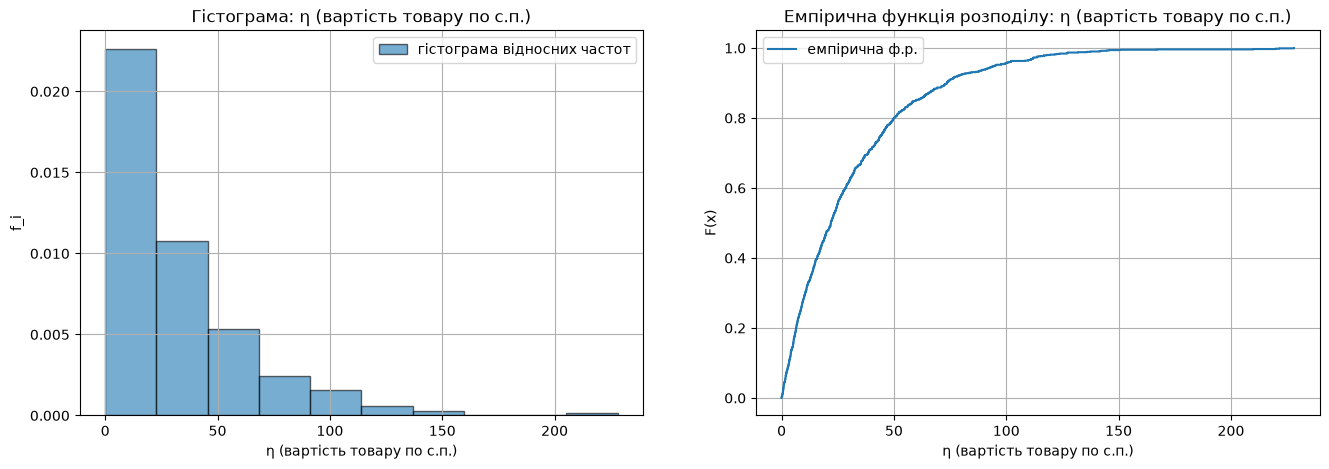

In [20]:
plot_hist_ecdf(eta, "η (вартість товару по с.п.)")

**Що бачимо.** Гістограма монотонно спадає від нуля — найбільше дешевих товарів, дорогі трапляються рідко. Емпірична функція розподілу швидко зростає біля нуля й опукла догори. Така форма характерна для експоненційного розподілу.

### Крок 2. Оцінка параметра $\theta=\lambda k$

Як сказано в підказці до лаби, $\lambda k$ — **один** параметр: розподіл $\eta_i$ залежить лише від добутку, тому з вибірки $\eta$ окремо $\lambda$ і $k$ не розрізнити. Позначимо $\theta=\lambda k$.

**Метод моментів**. Моментна функція $h(x)=x$, теоретичний момент $H(\theta)=\mathrm E_\theta\eta_1=\int_0^\infty x\,\theta e^{-\theta x}dx=1/\theta$. Прирівнюємо до емпіричного моменту $\bar\eta$:
$$
\frac1{\hat\theta}=\bar\eta\;\Longrightarrow\;\hat\theta^{(1)}=\frac{1}{\bar\eta}=\frac{n}{\sum_{i=1}^n\eta_i}.
$$

**Метод найбільшої вірогідності**:
$$
l(\theta)=\log\prod_{i=1}^n\theta e^{-\theta\eta_i}=n\log\theta-\theta\sum_{i=1}^n\eta_i,\qquad
l'(\theta)=\frac n\theta-\sum\eta_i=0\;\Longrightarrow\;\hat\theta^{MLE}=\frac1{\bar\eta}.
$$
Це максимум, бо $l''(\theta)=-n/\theta^2<0$. **Оцінки методу моментів і найбільшої вірогідності збігаються.**

**Медіанна оцінка**  — для порівняння. Оскільки $Q_{F_\theta}(1/2)=\log 2/\theta$, то $\hat\theta^{med}=\dfrac{\log 2}{\mathrm{med}(\eta)}$. Вона сильно консистентна і робастна.

**Яка точніша?**: коефіцієнти розсіювання $v_{\hat\theta^{(1)}}=\theta^2$ і $v_{\hat\theta^{med}}=\theta^2/(\log2)^2\approx2.08\,\theta^2$. Отже, ОМВ точніша, а медіанна оцінка потребує приблизно вдвічі більшого обсягу вибірки для тієї ж точності. Далі використовуємо $\hat\theta=1/\bar\eta$.

(Незміщеність і конзистентність такої оцінки детально доводимо в розділі 3 для $\hat\lambda=1/\bar\xi$; для $\hat\theta=1/\bar\eta$ усе ідентично із заміною $\lambda\to\lambda k$.)

In [21]:
theta_hat = 1 / eta_mean                       # оцінка λk (МM = ОМВ)
theta_med = math.log(2) / med(eta)             # медіанна оцінка
print("θ_hat = 1 / η̄ = 1 / {:.4f} = {:.6f}".format(eta_mean, theta_hat))
print("med(η) = {:.4f},  θ_med = log2 / med(η) = {:.6f}".format(med(eta), theta_med))
print("теоретична медіана log2 / θ_hat = {:.4f}".format(math.log(2) / theta_hat))

θ_hat = 1 / η̄ = 1 / 31.3233 = 0.031925
med(η) = 21.8956,  θ_med = log2 / med(η) = 0.031657
теоретична медіана log2 / θ_hat = 21.7117


### Детальний розрахунок

$$
\hat\theta=\widehat{\lambda k}=\frac{1}{\bar\eta}=\frac{1}{31.3233}=0.031925.
$$
Медіанна оцінка: $\mathrm{med}(\eta)=21.8956$, $\hat\theta^{med}=\dfrac{\log 2}{21.8956}=0.031657$ — близько до $\hat\theta$, що ще раз підтверджує модель. Теоретична медіана $\log 2/\hat\theta=21.7117$.

### Крок 3. Теоретична функція розподілу з підставленою оцінкою

$$
F_\eta(x)=1-e^{-0.031925\,x},\qquad f_\eta(x)=0.031925\,e^{-0.031925\,x},\qquad x\ge0.
$$

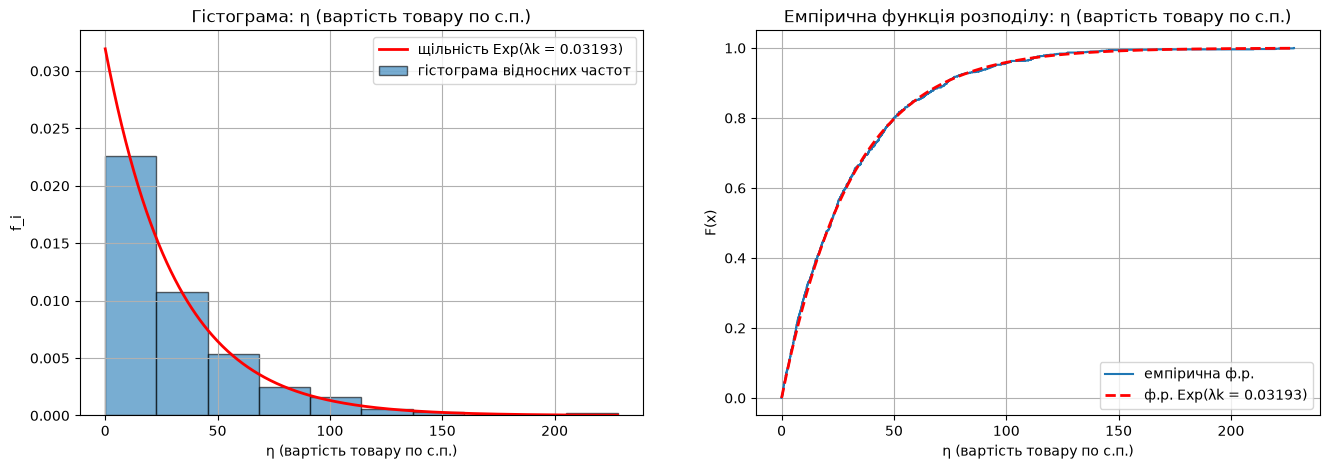

In [22]:
plot_hist_ecdf(eta, "η (вартість товару по с.п.)", lam=theta_hat, lam_name="λk")

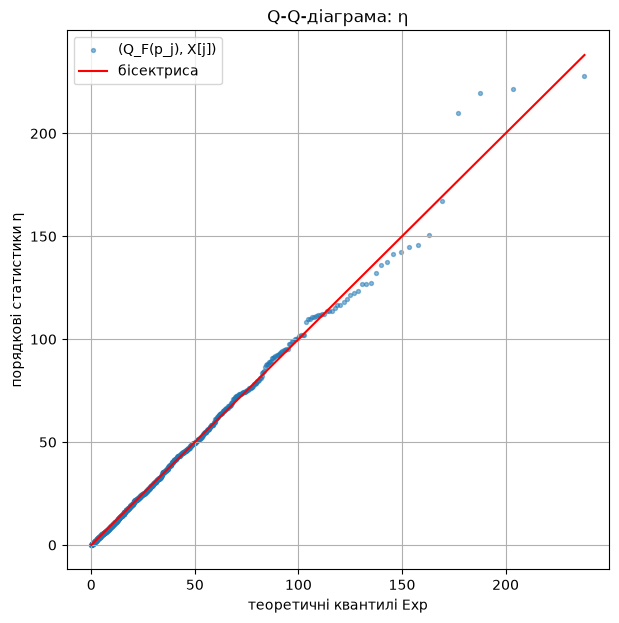

In [23]:
plot_qq_exp(eta, theta_hat, "η")

Щільність проходить по стовпчиках гістограми, теоретична функція розподілу майже зливається з емпіричною, точки Q-Q-діаграми лежать уздовж бісектриси (невеликий розкид на правому кінці — звичайне явище: «відхилення крайніх точок помітніші, ніж точок всередині діаграми»).

### Крок 4. Перевірка узгодженості тестом $\chi^2$ з групуванням

$H_0$: $\eta_i\sim Exp(\theta)$ для деякого $\theta>0$. Оцінюється один параметр, $d=1$. Рівень значущості $\alpha=0.05$.

In [24]:
table, chi2_emp, df, chi2_th, p_value = chi2_gof_exp(eta, theta_hat, alpha=0.05)
print("χ²_emp = {:.4f}".format(chi2_emp))
print("кількість комірок після об'єднання K = {},  df = K - d - 1 = {}".format(len(table), df))
print("χ²_th = Q_χ²_{}(0.95) = {:.4f}".format(df, chi2_th))
print("досягнутий рівень значущості p = {:.4f}".format(p_value))
table

χ²_emp = 2.6495
кількість комірок після об'єднання K = 8,  df = K - d - 1 = 6
χ²_th = Q_χ²_6(0.95) = 12.5916
досягнутий рівень значущості p = 0.8514


,комірка,n_i,p_i,n p_i,(n_i - n p_i)² / (n p_i)
0,(0.00; 22.81],516,0.517216,517.216303,0.002860
1,(22.81; 45.61],246,0.249666,249.666117,0.053834
2,(45.61; 68.42],122,0.120554,120.554114,0.017341
3,(68.42; 91.22],56,0.058211,58.210920,0.083973
4,(91.22; 114.03],36,0.028108,28.107803,2.215996
5,(114.03; 136.83],13,0.013572,13.572171,0.024121
6,(136.83; 159.63],6,0.006553,6.553477,0.046744
7,(159.63; inf],5,0.006119,6.119095,0.204666


Після об'єднання крайніх комірок з малими теоретичними частотами лишилося $K=8$ комірок, тож $df=K-1-1=6$.

$$
\chi^2_{emp}=2.650,\qquad \chi^2_{th}=Q_{\chi^2_{6}}(0.95)=12.592,\qquad p=0.851.
$$

Оскільки $\chi^2_{emp}\le\chi^2_{th}$ (рівносильно $p\ge0.05$), **тест приймає $H_0$**: дані узгоджуються з експоненційним розподілом.

## 2.3 Висновки до розділу 2

| Результат | Значення |
|---|---|
| $\bar\eta$ | 31.3233 грн |
| довірчий інтервал для $\mathrm E\eta$, $\alpha=0.05$ | [29.3618; 33.2848] |
| довірчий інтервал для $\mathrm E\eta$, $\alpha=0.01$ | [28.7455; 33.9012] |
| $\widehat{\lambda k}=1/\bar\eta$ (ММ = ОМВ) | 0.031925 |
| медіанна оцінка $\log2/\mathrm{med}(\eta)$ | 0.031657 |
| тест $\chi^2$ узгодженості | $\chi^2_{emp}=2.650$, $p=0.851$ |

- Середня вартість товару по с.п. ≈31 грн; з надійністю 0.99 — між ≈28.7455 і ≈33.9012 грн.
- Експоненційна модель $Exp(\lambda k)$ добре описує дані: гістограма, емпірична функція розподілу, Q-Q-діаграма, $S_0\approx\bar\eta$, тест $\chi^2$.

# 3. Інші товари ($\xi_i$)

Тут $\xi_i=\texttt{total}_i-\texttt{special\_proposition}_i$.

## 3.1 Оцінка математичного сподівання та довірчі інтервали

Теорія та сама, що в п. 2.1: $\bar\xi$ — незміщена, строго конзистентна, асимптотично нормальна оцінка з коефіцієнтом розсіювання $\mathrm D\xi_1$; інтервал $\bar\xi\pm x_p S_0(\xi)/\sqrt n$.

In [25]:
xi_sum = my_sum(xi)
xi_mean = my_mean(xi)
xi_S02 = S02(xi)

print("Σ total          = {:.4f}".format(my_sum(total)))
print("Σ η_i            = {:.4f}".format(eta_sum))
print("Σ ξ_i            = {:.4f}".format(xi_sum))
print("ξ̄ = Σ / n        = {:.4f}".format(xi_mean))
print("S0²(ξ)           = {:.4f}".format(xi_S02))
print("S0(ξ)            = {:.4f}".format(math.sqrt(xi_S02)))
print("S0(ξ) / sqrt(n)  = {:.4f}".format(math.sqrt(xi_S02 / n)))

rows = []
for p in [0.95, 0.99]:
    l, r = ci_mean(xi, p)
    rows.append([p, 1 - p, x_p(p), l, r, r - l])
pd.DataFrame(rows, columns=["надійність", "α", "x_p", "ліва межа", "права межа", "довжина"])

Σ total          = 130489.8483
Σ η_i            = 31323.3013
Σ ξ_i            = 99166.5470
ξ̄ = Σ / n        = 99.1665
S0²(ξ)           = 9540.1164
S0(ξ)            = 97.6735
S0(ξ) / sqrt(n)  = 3.0887


,надійність,α,x_p,ліва межа,права межа,довжина
0,0.95,0.05,1.959964,93.112791,105.220303,12.107512
1,0.99,0.01,2.575829,91.210563,107.122531,15.911969


### Детальний розрахунок

$$
\sum\xi_i=\sum\texttt{total}_i-\sum\eta_i=130489.85-31323.30=99166.55,\qquad \bar\xi=\frac{99166.55}{1000}=99.1665\ \text{грн}.
$$
$$
S_0^2(\xi)=9540.12,\qquad S_0(\xi)=97.6735,\qquad\frac{S_0(\xi)}{\sqrt n}=\frac{97.6735}{31.6228}=3.0887.
$$

**$\alpha=0.05$:** $\;1.9600\cdot3.0887=6.0538$, $\;\mu\in[93.1128;\;105.2203]$.

**$\alpha=0.01$:** $\;2.5758\cdot3.0887=7.9560$, $\;\mu\in[91.2106;\;107.1225]$.

Знову $S_0(\xi)=97.6735\approx\bar\xi=99.1665$.

## 3.2 Припущення $\xi_i\sim Exp(\lambda)$

За умовою $\lambda$ тут і в розділі 2 — той самий параметр: $\eta_i\sim Exp(\lambda k)$, $\xi_i\sim Exp(\lambda)$.

### Крок 1. Гістограма та емпірична функція розподілу

In [26]:
hist_table(xi, sturges(n))

,A_i,n_i,ν_i = n_i/n,f_i = n_i/(nh)
0,[0.10; 55.58],435,0.435,0.007840
1,(55.58; 111.06],235,0.235,0.004236
2,(111.06; 166.55],143,0.143,0.002577
3,(166.55; 222.03],73,0.073,0.001316
4,(222.03; 277.51],49,0.049,0.000883
5,(277.51; 332.99],33,0.033,0.000595
6,(332.99; 388.47],12,0.012,0.000216
7,(388.47; 443.96],9,0.009,0.000162
8,(443.96; 499.44],5,0.005,0.000090
9,(499.44; 554.92],6,0.006,0.000108


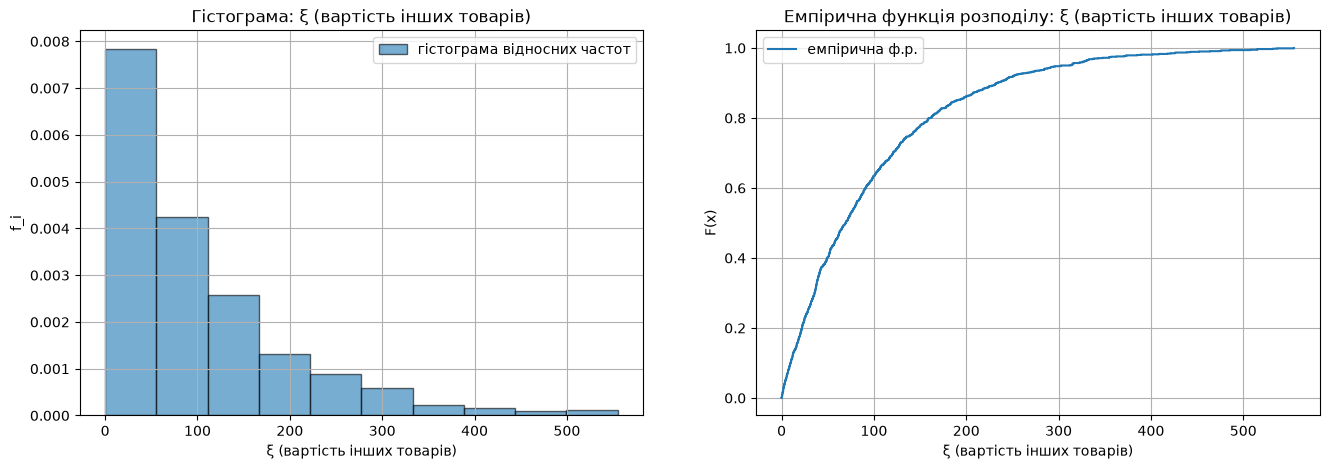

In [27]:
plot_hist_ecdf(xi, "ξ (вартість інших товарів)")

Картина така сама, як для $\eta$, лише масштаб по осі абсцис приблизно втричі більший.

### Крок 2. Оцінка $\lambda$

Як у п. 2.2, метод моментів і метод найбільшої вірогідності дають одну оцінку:
$$
\boxed{\hat\lambda=\frac1{\bar\xi}=\frac{n}{\sum_{i=1}^n\xi_i}}.
$$

In [28]:
lambda_hat = 1 / xi_mean
print("λ_hat = 1 / ξ̄ = 1 / {:.4f} = {:.6f}".format(xi_mean, lambda_hat))
print("незміщена версія (n - 1) / Σξ = {:.6f}".format((n - 1) / xi_sum))
print("med(ξ) = {:.4f},  теоретична медіана log2 / λ_hat = {:.4f}".format(med(xi), math.log(2) / lambda_hat))

λ_hat = 1 / ξ̄ = 1 / 99.1665 = 0.010084
незміщена версія (n - 1) / Σξ = 0.010074
med(ξ) = 69.4703,  теоретична медіана log2 / λ_hat = 68.7370


$$
\hat\lambda=\frac{1}{99.1665}=0.010084.
$$

### Чи є оцінка $\hat\lambda=1/\bar\xi$ незміщеною? Конзистентною?

Нагадаємо означення: оцінка $\hat\theta_n$ **незміщена**, якщо $\mathrm E_\theta\hat\theta_n=\theta$ для всіх $\theta$; **асимптотично незміщена**, якщо $\mathrm E_\theta\hat\theta_n\to\theta$; **конзистентна**, якщо $\hat\theta_n\to\theta$ за ймовірністю; **строго конзистентна**, якщо $\hat\theta_n\to\theta$ з імовірністю 1.

#### Крок А. Розподіл суми

За **теоремою про розподіл Ерланга**  сума $S=\sum_{i=1}^n\xi_i$ незалежних $Exp(\lambda)$ величин має щільність
$$
f_n(x)=\frac{\lambda(\lambda x)^{n-1}e^{-\lambda x}}{(n-1)!},\quad x\ge0,\qquad\text{тобто}\quad S\sim\Gamma(n,\lambda).
$$
(У книзі це доведено за індукцією через формулу згортки: $f_n=f_{n-1}*f_1$.)

#### Крок Б. Незміщеність — НІ

Обчислюємо $\mathrm E[1/S]$ за теоремою про обчислення математичного сподівання функції від величини через щільність. Скористаємось інтегралом $\int_0^\infty x^{a}e^{-\lambda x}dx=a!/\lambda^{a+1}$ (ціле $a\ge0$, інтегрування частинами):
$$
\mathrm E\Big[\frac1S\Big]=\int_0^\infty\frac1x\cdot\frac{\lambda^n x^{n-1}e^{-\lambda x}}{(n-1)!}dx
=\frac{\lambda^n}{(n-1)!}\int_0^\infty x^{n-2}e^{-\lambda x}dx=\frac{\lambda^n}{(n-1)!}\cdot\frac{(n-2)!}{\lambda^{n-1}}=\frac{\lambda}{n-1}.
$$
Оскільки $\hat\lambda=n/S$:
$$
\boxed{\mathrm E\hat\lambda=n\,\mathrm E\Big[\frac1S\Big]=\frac{n}{n-1}\lambda\neq\lambda}.
$$
Оцінка **зміщена вгору**, зсув $\frac{\lambda}{n-1}\to0$ — тобто вона **асимптотично незміщена**.

*Інтуїція:* функція $1/x$ опукла, тому за нерівністю Йенсена $\mathrm E[1/\bar\xi]\ge1/\mathrm E\bar\xi=\lambda$.

**Незміщена версія:** $\tilde\lambda=\frac{n-1}{n}\hat\lambda=\frac{n-1}{\sum\xi_i}$, $\mathrm E\tilde\lambda=\lambda$. Для наших даних $\tilde\lambda=0.010074$.

#### Крок В. Конзистентність — ТАК

*Спосіб 1.* $\hat\lambda$ — оцінка методу моментів з $H(\lambda)=1/\lambda$ і оберненою функцією $H^{-1}(x)=1/x$, неперервною на $(0,\infty)$. За **теоремою про строгу конзистентність оцінок методу моментів** $\hat\lambda\to\lambda$ м.н. Доведення: $\bar\xi\to1/\lambda$ м.н. за посиленим законом великих чисел, а $1/x$ неперервна в точці $1/\lambda>0$.

*Спосіб 2 (через дисперсію).* Аналогічно кроку Б:
$$
\mathrm E\Big[\frac{1}{S^2}\Big]=\frac{\lambda^n}{(n-1)!}\cdot\frac{(n-3)!}{\lambda^{n-2}}=\frac{\lambda^2}{(n-1)(n-2)},
$$
$$
\mathrm D\hat\lambda=n^2\,\mathrm E\Big[\frac1{S^2}\Big]-(\mathrm E\hat\lambda)^2=\frac{n^2\lambda^2}{(n-1)(n-2)}-\frac{n^2\lambda^2}{(n-1)^2}=\frac{n^2\lambda^2}{(n-1)^2(n-2)}\xrightarrow[n\to\infty]{}0.
$$
Зсув $\to0$ і дисперсія $\to0$ ⇒ $\mathrm E(\hat\lambda-\lambda)^2\to0$ ⇒ збіжність у середньому квадратичному ⇒ за ймовірністю.

**Асимптотична нормальність**: коефіцієнт розсіювання $v_{\hat\lambda}=\lambda^2$. Узгоджується: $n\,\mathrm D\hat\lambda=\frac{n^3\lambda^2}{(n-1)^2(n-2)}\to\lambda^2$.

#### Імітаційний експеримент

Беремо «справжнє» $\lambda=\hat\lambda$, для кожного $n$ генеруємо $B=4000$ вибірок, обчислюємо оцінки та порівнюємо середнє оцінок з $\frac{n}{n-1}\lambda$, а $n\cdot$(вибіркова дисперсія оцінок) — з коефіцієнтом розсіювання $\lambda^2$. Зауваження: `np.random.exponential` приймає **масштаб** $1/\lambda$.

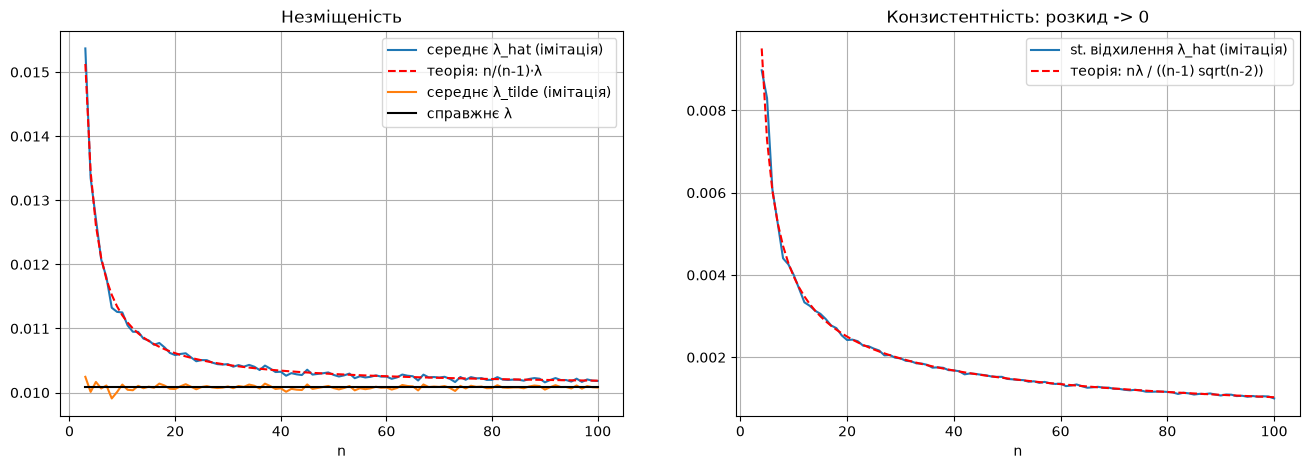

,n,середнє λ_hat,n/(n-1) λ,λ,n·D(λ_hat),v = λ²
0,10,0.011167,0.011204,0.010084,0.000148,0.000102
1,50,0.010304,0.010290,0.010084,0.000114,0.000102
2,200,0.010123,0.010135,0.010084,0.000100,0.000102
3,1000,0.010099,0.010094,0.010084,0.000104,0.000102


In [29]:
lambd = lambda_hat
B = 4000
ns = list(range(3, 101))

mean_hat, mean_unb, var_hat = [], [], []
for m in ns:
    x = np.random.exponential(1 / lambd, size=(B, m))    # B вибірок обсягу m
    est = 1 / x.mean(axis=1)                             # λ_hat
    mean_hat.append(est.mean())
    mean_unb.append(((m - 1) / m * est).mean())         # λ_tilde
    var_hat.append(est.var())

ns_arr = np.array(ns, dtype=float)
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
ax[0].plot(ns, mean_hat, label="середнє λ_hat (імітація)")
ax[0].plot(ns, ns_arr / (ns_arr - 1) * lambd, "r--", label="теорія: n/(n-1)·λ")
ax[0].plot(ns, mean_unb, label="середнє λ_tilde (імітація)")
ax[0].plot(ns, [lambd] * len(ns), "k", label="справжнє λ")
ax[0].set_xlabel("n")
ax[0].set_title("Незміщеність")
ax[0].grid()
ax[0].legend()

ax[1].plot(ns[1:], np.sqrt(var_hat[1:]), label="st. відхилення λ_hat (імітація)")
ax[1].plot(ns[1:], ns_arr[1:] * lambd / ((ns_arr[1:] - 1) * np.sqrt(ns_arr[1:] - 2)), "r--",
           label="теорія: nλ / ((n-1) sqrt(n-2))")
ax[1].set_xlabel("n")
ax[1].set_title("Конзистентність: розкид -> 0")
ax[1].grid()
ax[1].legend()
plt.show()

rows = []
for m in [10, 50, 200, 1000]:
    x = np.random.exponential(1 / lambd, size=(B, m))
    est = 1 / x.mean(axis=1)
    rows.append([m, est.mean(), m / (m - 1) * lambd, lambd, m * est.var(), lambd ** 2])
pd.DataFrame(rows, columns=["n", "середнє λ_hat", "n/(n-1) λ", "λ", "n·D(λ_hat)", "v = λ²"])

**Що показує імітація:** середнє $\hat\lambda$ лежить над справжнім $\lambda$ і йде по кривій $\frac{n}{n-1}\lambda$, а виправлена оцінка $\tilde\lambda$ «сидить» на $\lambda$. Розкид спадає до нуля, $n\cdot\mathrm D\hat\lambda$ наближається до коефіцієнта розсіювання $\lambda^2$.

### Крок 3. Теоретична функція розподілу з підставленою оцінкою

$$
F_\xi(x)=1-e^{-0.010084\,x},\qquad f_\xi(x)=0.010084\,e^{-0.010084\,x},\quad x\ge0.
$$

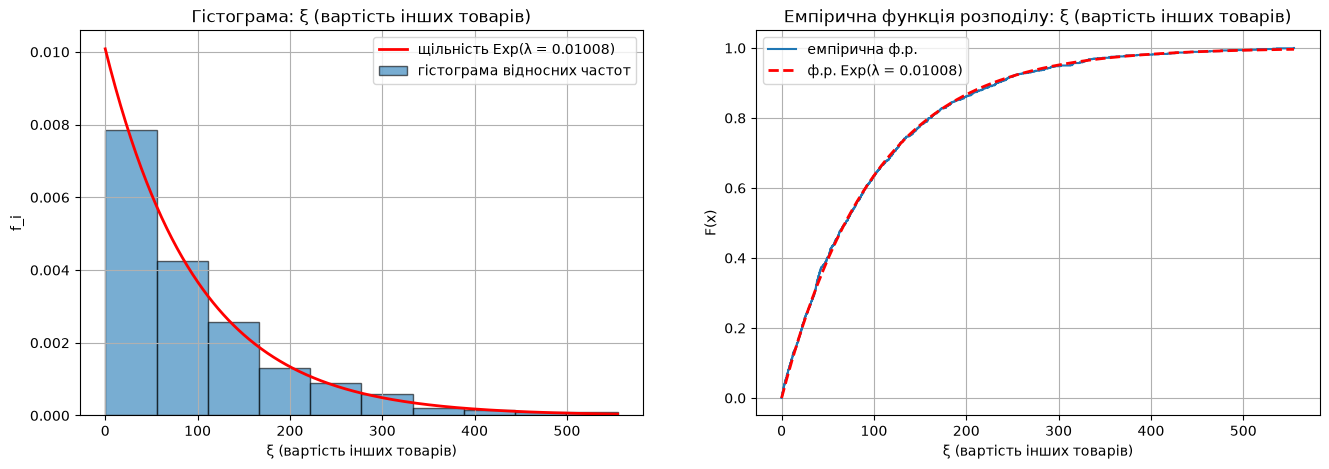

In [30]:
plot_hist_ecdf(xi, "ξ (вартість інших товарів)", lam=lambda_hat, lam_name="λ")

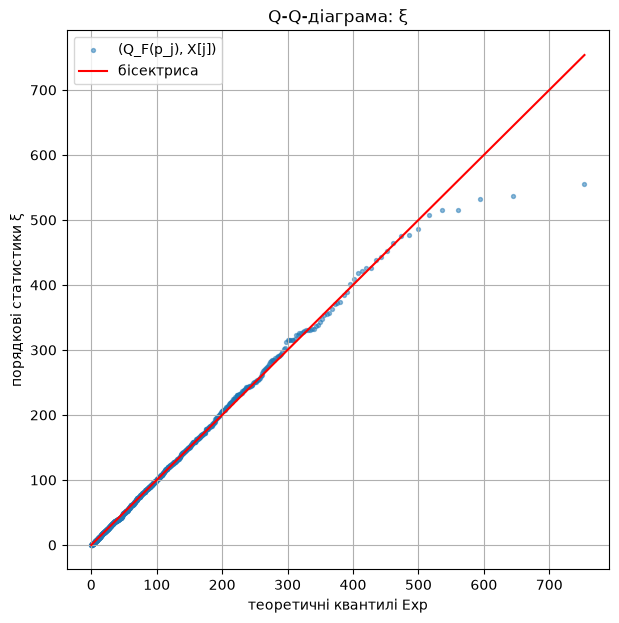

χ²_emp = 3.8344,  df = 7,  χ²_th = 14.0671,  p = 0.7986


,комірка,n_i,p_i,n p_i,(n_i - n p_i)² / (n p_i)
0,(0.00; 55.58],435,0.429079,429.079024,0.081705
1,(55.58; 111.06],235,0.244636,244.636097,0.379561
2,(111.06; 166.55],143,0.139811,139.811047,0.072737
3,(166.55; 222.03],73,0.079903,79.902880,0.596346
4,(222.03; 277.51],49,0.045665,45.664992,0.243563
5,(277.51; 332.99],33,0.026098,26.097826,1.825440
6,(332.99; 388.47],12,0.014915,14.915069,0.569735
7,(388.47; 499.44],14,0.013396,13.395605,0.027270
8,(499.44; inf],6,0.006497,6.497460,0.038087


In [31]:
plot_qq_exp(xi, lambda_hat, "ξ")
table, chi2_emp, df, chi2_th, p_value = chi2_gof_exp(xi, lambda_hat, alpha=0.05)
print("χ²_emp = {:.4f},  df = {},  χ²_th = {:.4f},  p = {:.4f}".format(chi2_emp, df, chi2_th, p_value))
table

Тест $\chi^2$ з групуванням: $\chi^2_{emp}=3.834$, $df=7$, $\chi^2_{th}=14.067$, $p=0.799$ — тест **приймає** $H_0$: $\xi_i\sim Exp(\lambda)$.
Теоретична медіана $\log2/\hat\lambda=68.7370$ проти вибіркової 69.4703.

## 3.3 Оцінка параметра $k$ (*)

### Попередня перевірка: чи незалежні $\xi$ та $\eta$?

Усі подальші викладки спираються на незалежність $\xi_i$ та $\eta_i$. Перевіримо її двома способами з.

**Кореляція Пірсона**. $H_0$: $\mathrm{cor}(\xi_1,\eta_1)=0$. Тест приймає $H_0$, якщо $|r|\le C_\alpha$, де
$$
C_\alpha=\sqrt{\frac{f_\alpha/(n-2)}{1+f_\alpha/(n-2)}},\qquad f_\alpha=Q_{F(1,n-2)}(1-\alpha).
$$
Оскільки $F(1,m)$ — розподіл квадрата величини з розподілом Стьюдента $T_m$, то $f_\alpha=\big(Q_{T_{n-2}}(1-\alpha/2)\big)^2$. (Строго кажучи, тест виведено для гауссових спостережень, тому додаємо непараметричну перевірку.)

**Тест $\chi^2$ незалежності**. Групуємо кожну змінну на 4 інтервали за вибірковими квартилями й будуємо таблицю спряженості $n_{ik}$. При незалежності теоретичні частоти $\bar n_{ik}=n\hat p_{i\cdot}\hat p_{\cdot k}=n_{i\cdot}n_{\cdot k}/n$,
$$
\chi^2_{emp}=\sum_{i,k}\frac{(n_{ik}-\bar n_{ik})^2}{\bar n_{ik}},\qquad df=(I-1)(K-1)=9,\qquad \chi^2_{th}=Q_{\chi^2_{df}}(1-\alpha).
$$

In [32]:
alpha = 0.05
r_xe = pearson_r(xi, eta)
f_alpha = t_quantile(1 - alpha / 2, n - 2) ** 2
C_alpha = math.sqrt(f_alpha / (n - 2) / (1 + f_alpha / (n - 2)))
print("r(ξ, η) = {:.4f}".format(r_xe))
print("f_α = Q_T(0.975)² = {:.4f},  C_α = {:.4f}".format(f_alpha, C_alpha))
print("|r| <= C_α ->", abs(r_xe) <= C_alpha)


def quartile_group(x):
    # номер інтервалу 0..3 за вибірковими квартилями (межі — порядкові статистики)
    y = sorted(x)
    m = len(y)
    q1, q2, q3 = y[m // 4 - 1], y[m // 2 - 1], y[3 * m // 4 - 1]
    g = []
    for v in x:
        if v <= q1:
            g.append(0)
        elif v <= q2:
            g.append(1)
        elif v <= q3:
            g.append(2)
        else:
            g.append(3)
    return g


def chi2_independence(a, b, I, K):
    table = [[0] * K for _ in range(I)]
    for u, v in zip(a, b):
        table[u][v] += 1
    m = len(a)
    row = [sum(table[i]) for i in range(I)]
    col = [sum(table[i][k] for i in range(I)) for k in range(K)]
    chi2 = 0.0
    min_exp = float("inf")
    for i in range(I):
        for k in range(K):
            e = row[i] * col[k] / m
            min_exp = min(min_exp, e)
            chi2 += (table[i][k] - e) ** 2 / e
    df = (I - 1) * (K - 1)
    return table, chi2, df, min_exp


tab, chi2_emp, df, min_exp = chi2_independence(quartile_group(xi), quartile_group(eta), 4, 4)
chi2_th = chi2_quantile(1 - alpha, df)
print("\nТаблиця спряженості (рядки — квартильні групи ξ, стовпчики — η):")
print(pd.DataFrame(tab, index=["ξ: Q1", "ξ: Q2", "ξ: Q3", "ξ: Q4"], columns=["η: Q1", "η: Q2", "η: Q3", "η: Q4"]))
print("мінімальна теоретична частота = {:.1f}".format(min_exp))
print("χ²_emp = {:.4f},  df = {},  χ²_th = {:.4f},  p = {:.4f}".format(
    chi2_emp, df, chi2_th, 1 - chi2_cdf(chi2_emp, df)))

r(ξ, η) = 0.0213
f_α = Q_T(0.975)² = 3.8508,  C_α = 0.0620
|r| <= C_α -> True

Таблиця спряженості (рядки — квартильні групи ξ, стовпчики — η):
       η: Q1  η: Q2  η: Q3  η: Q4
ξ: Q1     61     61     68     60
ξ: Q2     67     53     62     68
ξ: Q3     57     79     58     56
ξ: Q4     65     57     62     66
мінімальна теоретична частота = 62.5
χ²_emp = 9.5360,  df = 9,  χ²_th = 16.9190,  p = 0.3893


$|r(\xi,\eta)|=|0.0213|\le C_{0.05}=0.0620$, а тест $\chi^2$ незалежності дає $\chi^2_{emp}=9.536\le\chi^2_{th}=16.919$ ($p=0.389$). Обидва тести **приймають** гіпотезу незалежності. Надалі користуємось моделлю незалежних $\xi_i\sim Exp(\lambda)$ та $\eta_i\sim Exp(\lambda k)$.

### Побудова оцінки $k$

**Спосіб 1 — інваріантність ОМВ** (теорема про інваріантність оцінки максимальної вірогідності). Перейдемо від параметра $(\lambda,\theta)=(\lambda,\lambda k)$ до $(\lambda,k)$ взаємно однозначним відображенням $k=\theta/\lambda$. Тоді ОМВ для $k$ дорівнює $\hat\theta/\hat\lambda$.

**Спосіб 2 — метод моментів для векторних спостережень**. Спостереження — пари $(\xi_i,\eta_i)\in\mathbb R^2$, параметр $\vartheta=(\lambda,k)$, моментна функція $h(x,y)=(x,y)^T$:
$$
H(\lambda,k)=\mathrm E\,h(\xi_1,\eta_1)=\Big(\frac1\lambda,\;\frac1{\lambda k}\Big)^T .
$$
Рівняння $H(\hat\lambda,\hat k)=(\bar\xi,\bar\eta)^T$ дає $\hat\lambda=1/\bar\xi$ та $\frac{1}{\hat\lambda\hat k}=\bar\eta$. Обидва способи приводять до однієї оцінки:
$$
\boxed{\hat k=\frac{\widehat{\lambda k}}{\hat\lambda}=\frac{\bar\xi}{\bar\eta}}.
$$

In [33]:
k_hat = xi_mean / eta_mean
print("k_hat = ξ̄ / η̄ = {:.4f} / {:.4f} = {:.4f}".format(xi_mean, eta_mean, k_hat))
print("(те саме)  λk_hat / λ_hat = {:.6f} / {:.6f} = {:.4f}".format(theta_hat, lambda_hat, theta_hat / lambda_hat))
print("незміщена версія (n - 1) / n · k_hat = {:.4f}".format((n - 1) / n * k_hat))

k_hat = ξ̄ / η̄ = 99.1665 / 31.3233 = 3.1659
(те саме)  λk_hat / λ_hat = 0.031925 / 0.010084 = 3.1659
незміщена версія (n - 1) / n · k_hat = 3.1627


$$
\hat k=\frac{\bar\xi}{\bar\eta}=\frac{99.1665}{31.3233}=3.1659\qquad\Big(=\frac{0.031925}{0.010084}\Big).
$$
Інтенсивність цін товарів по с.п. приблизно в 3.2 раза вища, тобто товар по с.п. у середньому в ~3.2 раза **дешевший** за решту кошика.

### Консистентність $\hat k$ (*)

Застосовуємо теорему про консистентність моментних оцінок: $H(\lambda,k)$ існує для всіх $(\lambda,k)\in(0,\infty)^2$, обернена функція
$$
H^{-1}(a,b)=\Big(\frac1a,\;\frac ab\Big)
$$
існує і неперервна на множині можливих значень $(a,b)\in(0,\infty)^2$. Отже $(\hat\lambda,\hat k)=H^{-1}(\bar\xi,\bar\eta)\to(\lambda,k)$ м.н.

Розписано: за посиленим законом великих чисел $\bar\xi\to\frac1\lambda$ і $\bar\eta\to\frac{1}{\lambda k}$ м.н., функція $a/b$ неперервна в точці $\big(\frac1\lambda,\frac1{\lambda k}\big)$, бо знаменник додатний, тому $\hat k\to\frac{1/\lambda}{1/(\lambda k)}=k$ м.н. Оцінка **строго конзистентна** (отже й конзистентна).

### Зміщеність $\hat k$ (*)

$\xi$-вибірка та $\eta$-вибірка незалежні, тому $\bar\xi$ та $1/\bar\eta$ незалежні (теорема про перетворення незалежних величин). За **теоремою про математичне сподівання добутку незалежних величин**:
$$
\mathrm E\hat k=\mathrm E\,\bar\xi\cdot\mathrm E\Big[\frac1{\bar\eta}\Big].
$$
- $\mathrm E\,\bar\xi=\frac1\lambda$ (незміщеність вибіркового середнього).
- $T=\sum\eta_i$ має розподіл Ерланга $\Gamma(n,\lambda k)$, тому за кроком Б п. 3.2 (заміна $\lambda\to\lambda k$) $\mathrm E[1/T]=\frac{\lambda k}{n-1}$, отже $\mathrm E[1/\bar\eta]=n\,\mathrm E[1/T]=\frac{n\lambda k}{n-1}$.

$$
\boxed{\mathrm E\hat k=\frac1\lambda\cdot\frac{n\lambda k}{n-1}=\frac{n}{n-1}\,k\neq k}.
$$
Оцінка **зміщена** (завищує $k$), але **асимптотично незміщена**. Незміщена версія $\tilde k=\frac{n-1}{n}\cdot\frac{\bar\xi}{\bar\eta}=3.1627$.

**Точна дисперсія** (для повноти). $\mathrm E\bar\xi^2=\mathrm D\bar\xi+(\mathrm E\bar\xi)^2=\frac{1}{n\lambda^2}+\frac1{\lambda^2}=\frac{n+1}{n\lambda^2}$, $\;\mathrm E[1/\bar\eta^2]=n^2\mathrm E[1/T^2]=\frac{n^2(\lambda k)^2}{(n-1)(n-2)}$:
$$
\mathrm D\hat k=\mathrm E\bar\xi^2\,\mathrm E\Big[\frac1{\bar\eta^2}\Big]-(\mathrm E\hat k)^2=k^2\Big[\frac{n(n+1)}{(n-1)(n-2)}-\frac{n^2}{(n-1)^2}\Big]=\frac{k^2\,n(2n-1)}{(n-1)^2(n-2)}\xrightarrow[n\to\infty]{}0.
$$

### Асимптотична нормальність і довірчий інтервал для $k$

За **теоремою 8.4.1** [М] з розкладу (8.10): $\sqrt n(\hat\vartheta_n-\vartheta)\approx (H'(\vartheta))^{-1}\sqrt n(\hat h_n-\mathrm E\hat h_n)$. Зручніше взяти матрицю Якобі оберненої функції $H^{-1}(a,b)=(1/a,\;a/b)$ у точці $(a,b)=\big(\frac1\lambda,\frac1{\lambda k}\big)$:
$$
\frac{\partial H^{-1}}{\partial(a,b)}=\begin{pmatrix}-\frac1{a^2}&0\\[2pt]\frac1b&-\frac{a}{b^2}\end{pmatrix}=\begin{pmatrix}-\lambda^2&0\\ \lambda k&-\lambda k^2\end{pmatrix},\qquad
\mathbf D=\mathrm{cov}\,h(\xi_1,\eta_1)=\begin{pmatrix}\frac1{\lambda^2}&0\\0&\frac1{\lambda^2k^2}\end{pmatrix}.
$$
Коефіцієнт розсіювання $\hat k$ — другий діагональний елемент добутку $J\mathbf DJ^T$:
$$
v_{\hat k}=(\lambda k)^2\cdot\frac1{\lambda^2}+(\lambda k^2)^2\cdot\frac{1}{\lambda^2k^2}=k^2+k^2=2k^2
$$
(узгоджується з точною дисперсією: $n\,\mathrm D\hat k\to2k^2$). За (8.20) $k^\pm=\hat k\pm x_p\sqrt{2\hat k^2/n}$:

| Надійність | $x_p\sqrt{2\hat k^2/n}$ | Довірчий інтервал для $k$ |
|---|---|---|
| 0.95 | 1.9600 · 0.1416 = 0.2775 | [2.8884; 3.4434] |
| 0.99 | 2.5758 · 0.1416 = 0.3647 | [2.8012; 3.5306] |

#### Імітаційний експеримент

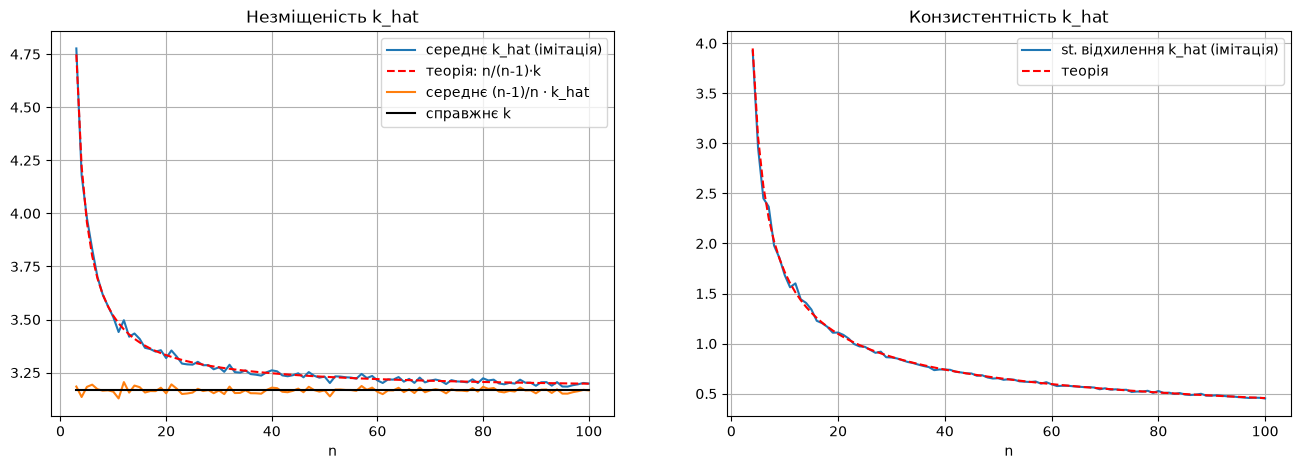

In [34]:
k_true = k_hat
lambd = lambda_hat
B = 4000
ns = list(range(3, 101))

mean_k, mean_k_unb, sd_k = [], [], []
for m in ns:
    x = np.random.exponential(1 / lambd, size=(B, m))              # ξ ~ Exp(λ)
    y = np.random.exponential(1 / (lambd * k_true), size=(B, m))   # η ~ Exp(λk)
    est = x.mean(axis=1) / y.mean(axis=1)
    mean_k.append(est.mean())
    mean_k_unb.append(((m - 1) / m * est).mean())
    sd_k.append(est.std())

ns_arr = np.array(ns, dtype=float)
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
ax[0].plot(ns, mean_k, label="середнє k_hat (імітація)")
ax[0].plot(ns, ns_arr / (ns_arr - 1) * k_true, "r--", label="теорія: n/(n-1)·k")
ax[0].plot(ns, mean_k_unb, label="середнє (n-1)/n · k_hat")
ax[0].plot(ns, [k_true] * len(ns), "k", label="справжнє k")
ax[0].set_xlabel("n")
ax[0].set_title("Незміщеність k_hat")
ax[0].grid()
ax[0].legend()

ax[1].plot(ns[1:], sd_k[1:], label="st. відхилення k_hat (імітація)")
ax[1].plot(ns[1:], k_true * np.sqrt(ns_arr[1:] * (2 * ns_arr[1:] - 1) / ((ns_arr[1:] - 1) ** 2 * (ns_arr[1:] - 2))),
           "r--", label="теорія")
ax[1].set_xlabel("n")
ax[1].set_title("Конзистентність k_hat")
ax[1].grid()
ax[1].legend()
plt.show()

Імітація підтверджує теорію: $\mathrm E\hat k$ йде по кривій $\frac{n}{n-1}k$, виправлена оцінка незміщена, розкид прямує до нуля.

## 3.4 Висновки до розділу 3

| Результат | Значення |
|---|---|
| $\bar\xi$ | 99.1665 грн |
| довірчий інтервал для $\mathrm E\xi$, $\alpha=0.05$ | [93.1128; 105.2203] |
| довірчий інтервал для $\mathrm E\xi$, $\alpha=0.01$ | [91.2106; 107.1225] |
| $\hat\lambda=1/\bar\xi$ | 0.010084 — зміщена, асимптотично незміщена, строго конзистентна |
| $\tilde\lambda=(n-1)/\sum\xi_i$ | 0.010074 — незміщена |
| $\hat k=\bar\xi/\bar\eta$ | 3.1659 — зміщена ($\mathrm E\hat k=\frac n{n-1}k$), строго конзистентна |
| тест $\chi^2$ узгодженості для $\xi$ | $\chi^2_{emp}=3.834$, $p=0.799$ |

- Решта кошика в середньому коштує ≈99 грн, товар по с.п. — ≈31 грн, тобто втричі дешевше.
- Обидві вартості добре описуються експоненційним розподілом і незалежні між собою.

# 4. Частка с.п. у замовленні

Розглядаємо величини
$$
u_i=\frac{\eta_i}{\xi_i+\eta_i}=\frac{\texttt{special\_proposition}_i}{\texttt{total}_i}\in(0,1)
$$
— частку вартості замовлення, яку становить товар по с.п.

**Змістовна гіпотеза.** Недоброчесний клієнт додає **дешевий** товар по с.п. до **дорогого** кошика, щоб не платити 20 грн за доставку, а потім повертає цей товар. Тоді в повернених замовленнях частка $u_i$ мала.

## 4.1 Як перевіряти залежність — теорія

Змінна `return` — категорійна (2 рівні), $u$ — числова. Залежність між числовою та категорійною змінною можна перевіряти, зокрема, групуючи числову змінну. Використаємо:

| Засіб | Що показує | Де в книзі |
|---|---|---|
| описові статистики по групах | середнє положення та розкид $u$ у повернених і неповернених | [М, розд. 4] |
| гістограми відносних частот двох груп на одному рисунку | порівняння розподілів двох наборів даних | [М, п. 7.4] |
| таблиця спряженості й тест $\chi^2$ незалежності | $H_0$: інтервал, у який потрапила частка $u$, і факт повернення незалежні | [М, п. 9.6.4] |
| тест за довірчими інтервалами | $H_0$: $\mathrm E[u\mid\text{пов.}]=\mathrm E[u\mid\text{не пов.}]$ | [М, п. 9.4] |

**Вибір основної гіпотези**: ми хочемо своїми даними переконати, що залежність *є*, тому основною беремо протилежну — **залежності немає**. Якщо тест її відхилить, це буде доказом.

In [35]:
u = eta / total    # u_i = η_i / (ξ_i + η_i)


def describe(x):
    y = sorted(x)
    return [len(x), my_mean(x), med(x), y[0], y[-1], math.sqrt(S02(x))]


rows = [
    ["повернено"] + describe(u[ret]) + [my_mean(eta[ret]), my_mean(xi[ret])],
    ["не повернено"] + describe(u[~ret]) + [my_mean(eta[~ret]), my_mean(xi[~ret])],
    ["усі замовлення"] + describe(u) + [my_mean(eta), my_mean(xi)],
]
pd.DataFrame(rows, columns=["група", "обсяг", "ū", "med(u)", "X[1]", "X[n]", "S0(u)", "η̄", "ξ̄"])

,група,обсяг,ū,med(u),X[1],X[n],S0(u),η̄,ξ̄
0,повернено,278,0.048081,0.045899,0.000083,0.099016,0.029446,8.204930,166.506479
1,не повернено,722,0.420655,0.357926,0.100090,0.993745,0.249052,40.224835,73.237875
2,усі замовлення,1000,0.317079,0.233131,0.000083,0.993745,0.269993,31.323301,99.166547


**Уже з описових статистик видно різку різницю:**

| | повернено | не повернено |
|---|---|---|
| середня частка $\bar u$ | 0.0481 (≈5%) | 0.4207 (≈42%) |
| середня вартість товару по с.п. $\bar\eta$ | 8.20 грн | 40.22 грн |
| середня вартість решти кошика $\bar\xi$ | 166.51 грн | 73.24 грн |

Найбільша частка серед повернених $X_{[n]}=0.09902$, а найменша серед неповернених $X_{[1]}=0.10009$. **Групи взагалі не перетинаються**: між ними проходить межа $u=0.1$.

## 4.2 Порівняння розподілів двох груп

Беремо **гістограми відносних частот**, бо обсяги груп різні (278 і 722). Для абсолютних частот гістограма меншої групи губилась би на фоні більшої.

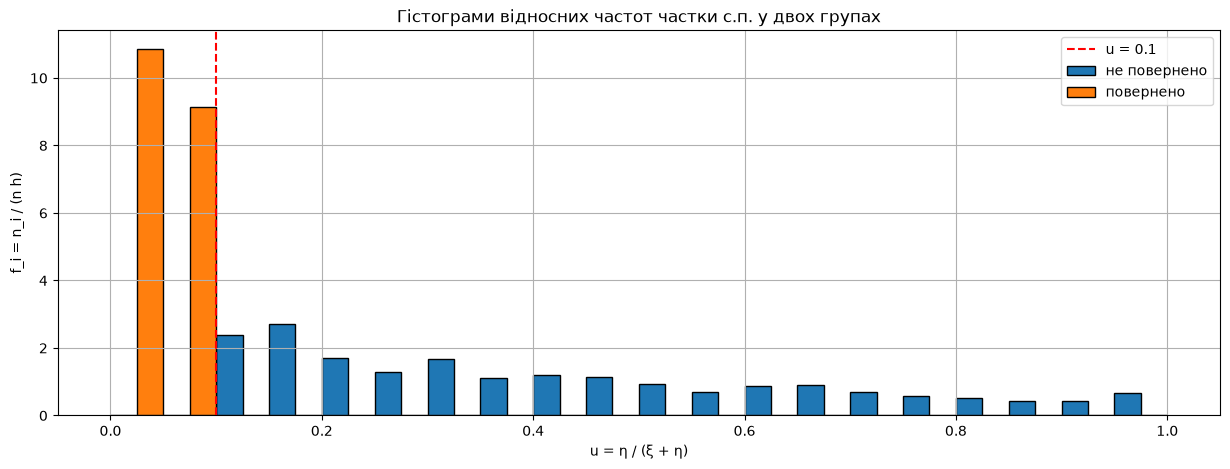

In [36]:
edges = [j / 20 for j in range(21)]      # однакові інтервали ширини 0.05 для обох груп
h = edges[1] - edges[0]


def rel_heights(x, edges):
    K = len(edges) - 1
    counts = [0] * K
    for v in x:
        i = math.ceil((v - edges[0]) / h) - 1
        i = min(max(i, 0), K - 1)
        counts[i] += 1
    return [c / (len(x) * h) for c in counts]


f_ret = rel_heights(u[ret], edges)
f_not = rel_heights(u[~ret], edges)
mid = [e + h / 2 for e in edges[:-1]]

plt.figure(figsize=(15, 5))
plt.bar([m - h / 4 for m in mid], f_not, width=h / 2, edgecolor="black", label="не повернено")
plt.bar([m + h / 4 for m in mid], f_ret, width=h / 2, edgecolor="black", label="повернено")
plt.axvline(0.1, color="red", ls="--", label="u = 0.1")
plt.xlabel("u = η / (ξ + η)")
plt.ylabel("f_i = n_i / (n h)")
plt.title("Гістограми відносних частот частки с.п. у двох групах")
plt.grid()
plt.legend()
plt.show()

Стовпчики розташовані поруч, щоб не перекривались. Розподіл частки у повернених замовленнях повністю зосереджений лівіше за $0.1$, у неповернених — правіше.

## 4.3 Таблиця спряженості та тест $\chi^2$ незалежності

**Змінна $A$** — номер інтервалу, куди потрапила частка: $A_1=[0;0.1]$, $A_i=(0.1(i-1);\,0.1i]$, $i=2,\dots,10$ ($I=10$). **Змінна $B$** — повернення ($K=2$). $H_0$: $A$ і $B$ незалежні, тобто $p_{ik}=p_{i\cdot}p_{\cdot k}$.

ОМВ: $\hat p_{i\cdot}=n_{i\cdot}/n$, $\hat p_{\cdot k}=n_{\cdot k}/n$. Теоретичні частоти $\bar n_{ik}=n\hat p_{i\cdot}\hat p_{\cdot k}$. Статистика та поріг:
$$
\chi^2_{emp}=\sum_{i=1}^{I}\sum_{k=1}^{K}\frac{(n_{ik}-\bar n_{ik})^2}{\bar n_{ik}},\qquad df=(I-1)(K-1)=9,\qquad\chi^2_{th}=Q_{\chi^2_{9}}(1-\alpha).
$$
Якщо $H_0$ правильна, частка повернень в усіх рядках таблиці має бути приблизно однаковою й рівною $\hat p_n=0.278$.

In [38]:
I, K = 10, 2
A = []
for v in u:
    i = math.ceil(v / 0.1) - 1
    A.append(min(max(i, 0), I - 1))
Bv = [1 if r else 0 for r in ret]          # 1 — повернено, 0 — ні

tab, chi2_emp, df, min_exp = chi2_independence(A, Bv, I, K)
rows = []
for i in range(I):
    row_sum = tab[i][0] + tab[i][1]
    left = "[" if i == 0 else "("
    rows.append([left + "{:.1f}; {:.1f}]".format(i / 10, (i + 1) / 10), tab[i][1], tab[i][0], row_sum,
                 tab[i][1] / row_sum, row_sum * nu_n / n])
display_tab = pd.DataFrame(rows, columns=["інтервал u", "n_i1 (повернено)", "n_i2 (не повернено)", "n_i·",
                                          "частка повернень", "теор. частота n̄_i1"])

for a_ in [0.05, 0.01]:
    print("α = {}:  χ²_th = Q_χ²_{}(1 - α) = {:.4f}".format(a_, df, chi2_quantile(1 - a_, df)))
print("χ²_emp = {:.2f},  df = {},  мінімальна теоретична частота = {:.2f}".format(chi2_emp, df, min_exp))
print("досягнутий рівень значущості p = 1 - F(χ²_emp) = {:.3e}".format(1 - chi2_cdf(chi2_emp, df)))
display_tab

α = 0.05:  χ²_th = Q_χ²_9(1 - α) = 16.9190
α = 0.01:  χ²_th = Q_χ²_9(1 - α) = 21.6660
χ²_emp = 1000.00,  df = 9,  мінімальна теоретична частота = 9.73
досягнутий рівень значущості p = 1 - F(χ²_emp) = 0.000e+00


,інтервал u,n_i1 (повернено),n_i2 (не повернено),n_i·,частка повернень,теор. частота n̄_i1
0,[0.0; 0.1],278,0,278,1.0,77.284
1,(0.1; 0.2],0,184,184,0.0,51.152
2,(0.2; 0.3],0,109,109,0.0,30.302
3,(0.3; 0.4],0,100,100,0.0,27.800
4,(0.4; 0.5],0,84,84,0.0,23.352
5,(0.5; 0.6],0,59,59,0.0,16.402
6,(0.6; 0.7],0,65,65,0.0,18.070
7,(0.7; 0.8],0,46,46,0.0,12.788
8,(0.8; 0.9],0,35,35,0.0,9.730
9,(0.9; 1.0],0,40,40,0.0,11.120


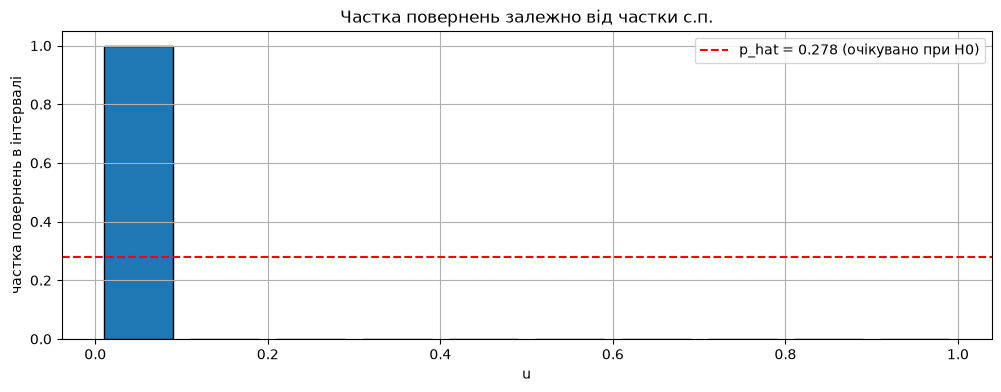

In [39]:
rates = [tab[i][1] / (tab[i][0] + tab[i][1]) for i in range(I)]
plt.figure(figsize=(12, 4))
plt.bar([i / 10 + 0.05 for i in range(I)], rates, width=0.08, edgecolor="black")
plt.axhline(p_hat, color="red", ls="--", label="p_hat = {:.3f} (очікувано при H0)".format(p_hat))
plt.xlabel("u")
plt.ylabel("частка повернень в інтервалі")
plt.title("Частка повернень залежно від частки с.п.")
plt.grid()
plt.legend()
plt.show()

**Застосовність тесту.** Мінімальна теоретична частота $9.73\ge5$, тож асимптотичний тест коректний.

**Результат.** $\chi^2_{emp}=1000.00$, що значно перевищує пороги $\chi^2_{th}=16.919$ ($\alpha=0.05$) і $21.666$ ($\alpha=0.01$). Досягнутий рівень значущості практично нульовий. **$H_0$ відхиляється: повернення залежать від частки с.п.**

Графік показує характер залежності. Якби $H_0$ була правильна, усі стовпчики стояли б біля червоної лінії. Натомість маємо «сходинку»: для $u\le0.1$ частка повернень дорівнює **1**, для $u>0.1$ — **0**.

## 4.4 Тест за довірчими інтервалами

$H_0$: $\mu_1=\mu_0$, де $\mu_1=\mathrm E[u\mid\text{повернено}]$, $\mu_0=\mathrm E[u\mid\text{не повернено}]$.

Для кожної групи будуємо асимптотичний довірчий інтервал (8.20) для математичного сподівання: $\bar u_g\pm x_p S_0(u_g)/\sqrt{n_g}$. Тест приймає $H_0$, якщо інтервали мають спільну точку, і відхиляє, якщо не перетинаються.

Інтервали мають бути **одночасними**. Групи — незалежні підвибірки, тож за (9.11) з $m=2$ для загального рівня $\alpha_0$ кожен інтервал будуємо з рівнем $\alpha=1-\sqrt{1-\alpha_0}$.

In [40]:
rows = []
for alpha0 in [0.05, 0.01]:
    alpha_each = 1 - math.sqrt(1 - alpha0)          # формула (9.11), m = 2
    p_each = 1 - alpha_each
    l1, r1 = ci_mean(u[ret], p_each)
    l0, r0 = ci_mean(u[~ret], p_each)
    intersect = not (r1 < l0 or r0 < l1)
    rows.append([alpha0, alpha_each, x_p(p_each), l1, r1, l0, r0, intersect])

pd.DataFrame(rows, columns=["α0", "α кожного", "x_p", "повернено: ліва", "повернено: права",
                            "не повернено: ліва", "не повернено: права", "перетинаються?"])

,α0,α кожного,x_p,повернено: ліва,повернено: права,не повернено: ліва,не повернено: права,перетинаються?
0,0.05,0.025321,2.236477,0.044131,0.052031,0.399926,0.441384,False
1,0.01,0.005013,2.806225,0.043125,0.053037,0.394645,0.446665,False


Для $\alpha_0=0.05$ кожен інтервал будуємо з $\alpha=1-\sqrt{0.95}=0.02532$:

| $\alpha_0$ | Повернено | Не повернено |
|---|---|---|
| 0.05 | [0.0441; 0.0520] | [0.3999; 0.4414] |
| 0.01 | [0.0431; 0.0530] | [0.3946; 0.4467] |

Інтервали **не перетинаються** і розташовані дуже далеко один від одного. Тест відхиляє $H_0$: середня частка с.п. у повернених замовленнях значуще менша.

## 4.5 Хто повертає: діаграма розсіювання

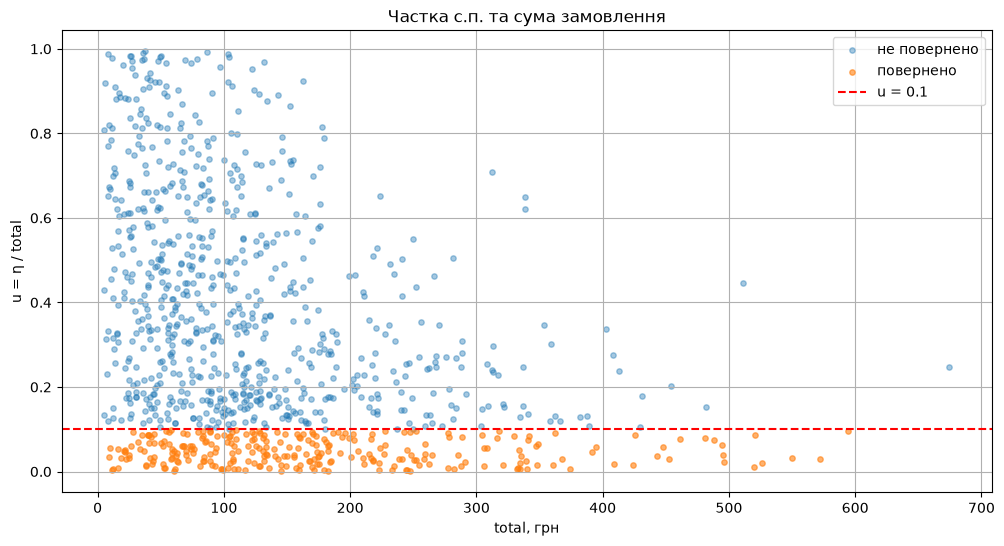

найбільша частка серед повернених    X[n] = 0.09902
найменша частка серед неповернених   X[1] = 0.10009


In [41]:
plt.figure(figsize=(12, 6))
plt.scatter(total[~ret], u[~ret], alpha=0.4, s=15, label="не повернено")
plt.scatter(total[ret], u[ret], alpha=0.6, s=15, label="повернено")
plt.axhline(0.1, color="red", ls="--", label="u = 0.1")
plt.xlabel("total, грн")
plt.ylabel("u = η / total")
plt.title("Частка с.п. та сума замовлення")
plt.grid()
plt.legend()
plt.show()

print("найбільша частка серед повернених    X[n] = {:.5f}".format(max(u[ret])))
print("найменша частка серед неповернених   X[1] = {:.5f}".format(min(u[~ret])))

Усі повернені замовлення лежать нижче червоної лінії, усі неповернені — вище. Поведінку клієнтів описує правило
$$
\boxed{p_i=\mathbb 1\Big\{\frac{\eta_i}{\xi_i+\eta_i}\le0.1\Big\}}.
$$

## 4.6 Оцінка обсягу недоброчесних дій

Замовлення з $u\le0.1$ і поверненням трактуємо як **зловживання**: клієнт отримує безкоштовну доставку кошика в середньому за 166.51 грн завдяки товару по с.п. за 8.20 грн, який потім безкоштовно повертає. Оскільки такі замовлення збігаються з усіма поверненнями, для їх частки годиться довірчий інтервал із розділу 1.

| Показник | Значення |
|---|---|
| кількість таких замовлень | 278 з 1000 (частка 0.278, довірчий інтервал при $\alpha=0.05$: [0.2502; 0.3058]) |
| недоотримана плата за доставку | $20\cdot278=5560$ грн на 1000 замовлень |
| те саме на 1000 замовлень, $\alpha=0.05$ | $20\cdot1000\cdot[0.2502;\,0.3058]\approx[5004;\,6116]$ грн |
| вартість повернених товарів по с.п. | 2280.97 грн (7.3% усіх продажів с.п.) |
| вартість «безкоштовно доставлених» інших товарів | 46288.80 грн |

До цього слід додати витрати на зворотну логістику повернених товарів, яких у даних немає.

## 4.7 Висновки до розділу 4

Повернення **залежать** від частки товару по с.п., і залежність детермінована: *усі* замовлення з часткою с.п. не більше 10% повернені, *жодне* з більшою часткою не повернене. Це доведено:
- описовими статистиками й порівнянням гістограм відносних частот [М, п. 7.4];
- тестом $\chi^2$ незалежності [М, п. 9.6.4]: $\chi^2_{emp}=1000.00\gg\chi^2_{th}$;
- тестом за одночасними довірчими інтервалами [М, п. 9.4]: інтервали для $\mathrm E[u]$ у групах не перетинаються.

Гіпотеза керівництва підтверджується. **Рекомендація:** обмежити безкоштовну доставку замовленнями, де частка с.п. не менша за певний поріг, або брати 20 грн за доставку при поверненні товару по с.п.

# 4.8 Теоретична задача — варіант 1

> **Чи можливо лише за вибіркою з $\dfrac{\eta_i}{\xi_i+\eta_i}$ оцінити параметри $\lambda$ та $k$?**

Модель: $\xi\sim Exp(\lambda)$, $\eta\sim Exp(\lambda k)$ незалежні. Позначимо $U=\dfrac{\eta}{\xi+\eta}\in(0,1)$; спостерігається кратна вибірка $u=(u_1,\dots,u_n)$.

**Коротка відповідь:** $k$ — **можна**, $\lambda$ — **неможливо**.

## Крок 1. Розподіл $U$

Задача знайти розподіл $\xi_1/(\xi_1+\xi_2)$ для незалежних показникових величин з різними параметрами.

Для $u\in(0,1)$:
$$
\{U\le u\}=\{\eta\le u(\xi+\eta)\}=\{\eta(1-u)\le u\,\xi\}=\{\eta\le a\,\xi\},\qquad a=\frac{u}{1-u}.
$$
За незалежністю $\xi$ та $\eta$ (сумісна щільність дорівнює добутку щільностей та теоремою Фубіні:
$$
\mathrm P(\eta\le a\xi)=\int_0^\infty\lambda e^{-\lambda x}\,\mathrm P(\eta\le ax)\,dx=\int_0^\infty\lambda e^{-\lambda x}\big(1-e^{-\lambda k a x}\big)dx
=1-\lambda\int_0^\infty e^{-\lambda(1+ka)x}dx=1-\frac{1}{1+ka}=\frac{ka}{1+ka}.
$$
**Параметр $\lambda$ скоротився.** Підставляємо $a=\frac{u}{1-u}$:
$$
\boxed{F_U(u)=\frac{k\frac{u}{1-u}}{1+k\frac{u}{1-u}}=\frac{ku}{1-u+ku}=\frac{ku}{1+(k-1)u},\qquad 0<u<1.}
$$
Щільність — похідна дробу:
$$
f_U(u)=\frac{k\big(1+(k-1)u\big)-ku(k-1)}{\big(1+(k-1)u\big)^2}=\boxed{\frac{k}{\big(1+(k-1)u\big)^2}}.
$$
Перевірки: $F_U(0)=0$, $F_U(1)=k/k=1$; при $k=1$ маємо $F_U(u)=u$, тобто $U\sim Unif(0,1)$.

## Крок 2. Чому $\lambda$ оцінити неможливо

Для оцінювання необхідно, щоб розподіл даних **однозначно** визначався оцінюваними параметрами.У суміші двох нормальних розподілів переставлення $\mu_1$ і $\mu_2$ не змінює розподілу даних, тому за даними їх не розрізнити.

У нас розподіл $U$ залежить **лише від $k$**. Отже, для $(\lambda_1,k)$ і $(\lambda_2,k)$ вибірка $u$ має однаковий розподіл. Припустимо, що існує конзистентна оцінка $T_n(u)\to\lambda$ за ймовірністю при всіх $(\lambda,k)$. Розподіл $T_n$ однаковий при $(\lambda_1,k)$ і $(\lambda_2,k)$, тож він мав би зосереджуватись одночасно біля $\lambda_1$ і біля $\lambda_2\ne\lambda_1$ — суперечність. **Конзистентної оцінки $\lambda$ за вибіркою часток не існує.**

*Змістовне пояснення.* Якщо всі ціни помножити на $c>0$ (наприклад, перейти від гривень до копійок), то $c\xi\sim Exp(\lambda/c)$, $c\eta\sim Exp(\lambda k/c)$: $\lambda$ змінюється, $k$ — ні, а частка $\frac{c\eta}{c\xi+c\eta}=U$ лишається тією самою. Частка — безрозмірна величина, вона «не знає» масштабу цін, а $\lambda$ і є параметром масштабу.

## Крок 3. Чому $k$ оцінити можна

При фіксованому $u\in(0,1)$:
$$
\frac{\partial F_U(u)}{\partial k}=\frac{u\big(1+(k-1)u\big)-ku\cdot u}{\big(1+(k-1)u\big)^2}=\frac{u(1-u)}{\big(1+(k-1)u\big)^2}>0 .
$$
Функція розподілу **строго монотонна** по $k$, тому різним $k$ відповідають різні розподіли. Побудуємо оцінки трьома методами.

### (а) Метод моментів

Моментна функція $h(u)=u$. Для величини зі значеннями в $[0,1]$: $\mathrm E\,U=\int_0^1\big(1-F_U(u)\big)du$, а $1-F_U(u)=\frac{1-u}{1+(k-1)u}$. Позначимо $a=k-1$ і розкладемо дріб: $\frac{1-u}{1+au}=-\frac1a+\frac{1+1/a}{1+au}$. Тоді
$$
H(k)=\mathrm E_k U=-\frac1a+\frac{1+a}{a^2}\log(1+a)=\frac{k\log k-k+1}{(k-1)^2}\quad(k\ne1),\qquad H(1)=\tfrac12 .
$$
Функція $H$ спадає (графік нижче), тому рівняння $H(\hat k)=\bar u$ має єдиний корінь. Явно воно не розв'язується, тому, шукаємо корінь чисельно — методом бісекції. $H^{-1}$ неперервна, тож за теоремою оцінка $\hat k^{MM}$ строго консистентна.

### (б) Метод квантилів — медіанна оцінка

Теоретична медіана: $F_U(q)=\frac12\iff 2kq=1+(k-1)q\iff q(k+1)=1$, тобто $Q_{F_U}(1/2)=\frac{1}{1+k}$. Прирівнюємо до вибіркової медіани:
$$
\boxed{\hat k^{med}=\frac{1-\mathrm{med}(u)}{\mathrm{med}(u)}}.
$$
$F_U$ строго зростає, тому за теоремою про строгу конзистентність вибіркових квантилей  $\mathrm{med}(u)\to\frac1{1+k}$ м.н., а функція $\frac{1-q}{q}$ неперервна ⇒ $\hat k^{med}$ строго консистентна.

### (в) Метод найбільшої вірогідності

$$
l(k)=\sum_{i=1}^n\log f_U(u_i)=n\log k-2\sum_{i=1}^n\log\big(1+(k-1)u_i\big),\qquad
l'(k)=\frac nk-2\sum_{i=1}^n\frac{u_i}{1+(k-1)u_i}.
$$
Рівняння $l'(k)=0$ явно не розв'язується, тому корінь шукаємо бісекцією. При $k\to0^+$ маємо $l'(k)\to+\infty$, при великих $k$ — $l'(k)<0$. Єдиність максимуму видно з графіка $l(k)$.

In [48]:
def H_U(k):                       # E U як функція k
    if abs(k - 1) < 1e-8:
        return 0.5
    return (k * math.log(k) - k + 1) / (k - 1) ** 2


def loglik_U(k, u):
    s = 0.0
    for v in u:
        s += math.log(1 + (k - 1) * v)
    return len(u) * math.log(k) - 2 * s


def score_U(k, u):
    s = 0.0
    for v in u:
        s += v / (1 + (k - 1) * v)
    return len(u) / k - 2 * s


u_mean = my_mean(u)
u_med = med(u)

# (а) метод моментів: H спадає, тому розв'язуємо -H(k) = -ū бісекцією
k_mm = bisection(lambda k: -H_U(k), -u_mean, 0.01, 100.0)
# (б) медіанна оцінка
k_med = (1 - u_med) / u_med
# (в) ОМВ: l'(k) спадає по k у околі кореня; розв'язуємо -l'(k) = 0
k_mle = bisection(lambda k: -score_U(k, u), 0.0, 0.01, 100.0, eps=1e-9)

print("ū = {:.5f},  med(u) = {:.5f}".format(u_mean, u_med))
print("(а) метод моментів:   H(k_MM) = ū  ->  k_MM  = {:.4f}   (перевірка H(k_MM) = {:.5f})".format(k_mm, H_U(k_mm)))
print("(б) медіанна оцінка:  (1 - med)/med ->  k_med = {:.4f}".format(k_med))
print("(в) ОМВ:              l'(k) = 0     ->  k_MLE = {:.4f}   (перевірка l'(k_MLE) = {:.2e})".format(k_mle, score_U(k_mle, u)))
print("\nдля порівняння, з розділу 3 (використовує ξ і η окремо): k_hat = ξ̄/η̄ = {:.4f}".format(k_hat))

ū = 0.31708,  med(u) = 0.23313
(а) метод моментів:   H(k_MM) = ū  ->  k_MM  = 3.1436   (перевірка H(k_MM) = 0.31708)
(б) медіанна оцінка:  (1 - med)/med ->  k_med = 3.2894
(в) ОМВ:              l'(k) = 0     ->  k_MLE = 3.2085   (перевірка l'(k_MLE) = 7.06e-09)

для порівняння, з розділу 3 (використовує ξ і η окремо): k_hat = ξ̄/η̄ = 3.1659


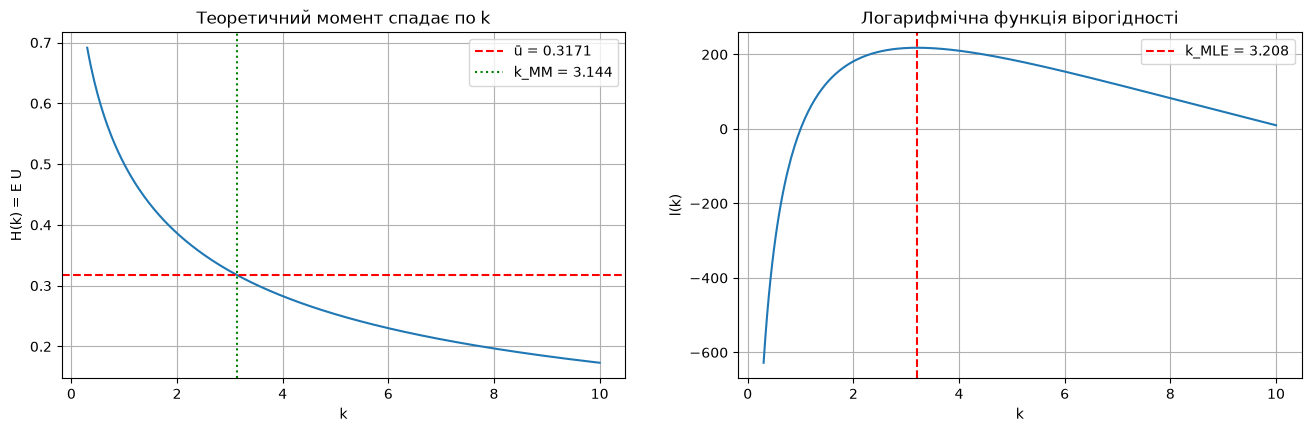

In [49]:
ks = np.linspace(0.3, 10, 300)
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
ax[0].plot(ks, [H_U(kk) for kk in ks])
ax[0].axhline(u_mean, color="red", ls="--", label="ū = {:.4f}".format(u_mean))
ax[0].axvline(k_mm, color="green", ls=":", label="k_MM = {:.3f}".format(k_mm))
ax[0].set_xlabel("k")
ax[0].set_ylabel("H(k) = E U")
ax[0].set_title("Теоретичний момент спадає по k")
ax[1].plot(ks, [loglik_U(kk, u) for kk in ks])
ax[1].axvline(k_mle, color="red", ls="--", label="k_MLE = {:.3f}".format(k_mle))
ax[1].set_xlabel("k")
ax[1].set_ylabel("l(k)")
ax[1].set_title("Логарифмічна функція вірогідності")
for a_ in ax:
    a_.grid()
    a_.legend()
plt.show()

### Детальний розрахунок

**(а)** $\bar u=0.31708$; розв'язок рівняння $\frac{k\log k-k+1}{(k-1)^2}=0.31708$: $\hat k^{MM}=3.1436$.

**(б)** $\mathrm{med}(u)=0.23313$, $\;\hat k^{med}=\dfrac{1-0.23313}{0.23313}=\dfrac{0.76687}{0.23313}=3.2894$.

**(в)** Корінь $l'(k)=0$: $\hat k^{MLE}=3.2085$. Графік $l(k)$ має єдиний максимум.

| Оцінка $k$ | Які дані використовує | Значення |
|---|---|---|
| $\hat k=\bar\xi/\bar\eta$ (розділ 3) | $\xi_i$ і $\eta_i$ окремо | 3.1659 |
| $\hat k^{MM}$ | лише $u_i$ | 3.1436 |
| $\hat k^{med}$ | лише $u_i$ | 3.2894 |
| $\hat k^{MLE}$ | лише $u_i$ | 3.2085 |

Усі чотири оцінки узгоджуються: $k\approx3.2$.

## Крок 4. Яка оцінка точніша: коефіцієнти розсіювання

**Медіанна оцінка**, формула (8.14): $v=\dfrac{1}{4\big(f(\mathrm{med})\,q'_{1/2}(k)\big)^2}$, де $q_{1/2}(k)=\frac{1}{1+k}$ — теоретична медіана.
- $q'_{1/2}(k)=-\frac{1}{(1+k)^2}$;
- $f_U\big(\frac1{1+k}\big)=\dfrac{k}{\big(1+\frac{k-1}{k+1}\big)^2}=\dfrac{k}{\big(\frac{2k}{k+1}\big)^2}=\dfrac{(1+k)^2}{4k}$;
- $4\big(f\,q'\big)^2=4\cdot\dfrac{(1+k)^4}{16k^2}\cdot\dfrac{1}{(1+k)^4}=\dfrac1{4k^2}$, отже $\boxed{v_{med}=4k^2}$.

**ОМВ**: $v_{MLE}=1/I(k)$, де $I(k)=\mathrm E\big(\frac{\partial}{\partial k}\log f_U(U)\big)^2$ — інформація Фішера на одне спостереження. Маємо $\frac{\partial}{\partial k}\log f_U(u)=\frac1k-\frac{2u}{1+(k-1)u}$. Зробимо заміну $w=\frac{u}{1+(k-1)u}$: тоді $dw=\frac{du}{(1+(k-1)u)^2}$, тобто $f_U(u)\,du=k\,dw$, а $w$ пробігає $[0,1/k]$. Отже, величина $W=\frac{U}{1+(k-1)U}$ має **рівномірний** розподіл $Unif(0,1/k)$, і
$$
\mathrm E\Big(\frac1k-2W\Big)=\frac1k-2\cdot\frac{1}{2k}=0,\qquad
I(k)=\mathrm E\Big(\frac1k-2W\Big)^2=4\,\mathrm D W=4\cdot\frac{(1/k)^2}{12}=\frac{1}{3k^2}\;\Longrightarrow\;\boxed{v_{MLE}=3k^2}.
$$

**Метод моментів**: $v_{MM}=\dfrac{\mathrm D\,U}{(H'(k))^2}$. За правилом похідної частки $H'(k)=\dfrac{2(k-1)-(k+1)\log k}{(k-1)^3}$; $\mathrm D U=\mathrm E U^2-(\mathrm E U)^2$, де $\mathrm E U^2=\int_0^1u^2f_U(u)\,du$ рахуємо формулою Сімпсона.

**Оцінка з розділу 3** (використовує $\xi$ та $\eta$ окремо): $v=2k^2$.

In [50]:
def dH_U(k):
    return (2 * (k - 1) - (k + 1) * math.log(k)) / (k - 1) ** 3


def var_U(k):
    EU2 = simpson(lambda s: s * s * k / (1 + (k - 1) * s) ** 2, 0.0, 1.0)
    return EU2 - H_U(k) ** 2


kk = k_mle
v_mm = var_U(kk) / dH_U(kk) ** 2
rows = [
    ["k_hat = ξ̄/η̄ (розділ 3)", "2k²", 2 * kk ** 2, 1.0],
    ["ОМВ за u", "3k²", 3 * kk ** 2, 1.5],
    ["метод моментів за u", "D U / H'(k)²", v_mm, v_mm / (2 * kk ** 2)],
    ["медіанна за u", "4k²", 4 * kk ** 2, 2.0],
]
print("значення при k = k_MLE = {:.4f}".format(kk))
pd.DataFrame(rows, columns=["оцінка", "формула v", "v", "v / v(ξ̄/η̄)"])

значення при k = k_MLE = 3.2085


,оцінка,формула v,v,v / v(ξ̄/η̄)
0,k_hat = ξ̄/η̄ (розділ 3),2k²,20.588439,1.000000
1,ОМВ за u,3k²,30.882658,1.500000
2,метод моментів за u,D U / H'(k)²,33.782448,1.640846
3,медіанна за u,4k²,41.176877,2.000000


**Інтерпретація через відносну асимптотичну ефективність**: відношення коефіцієнтів розсіювання показує, у скільки разів треба збільшити обсяг вибірки, щоб досягти тієї самої точності.

- Серед оцінок лише за частками найточніша ОМВ ($3k^2$), далі метод моментів (≈1.641·$2k^2$), найменш точна — медіанна ($4k^2$).
- Навіть найкраща оцінка за частками гірша за $\bar\xi/\bar\eta$ ($2k^2$): переходячи від пар $(\xi_i,\eta_i)$ до частки, ми **втрачаємо інформацію** — саме ту, що стосується масштабу $\lambda$.

**Довірчий інтервал для $k$ лише за частками** (ОМВ, $v=3\hat k^2$): $\sqrt{3\hat k^2/n}=0.1757$.

| Надійність | $x_p\sqrt{3\hat k^2/n}$ | Інтервал |
|---|---|---|
| 0.95 | 0.3444 | [2.8640; 3.5529] |
| 0.99 | 0.4527 | [2.7558; 3.6611] |

### Перевірка моделі для $U$: гістограма та емпірична функція розподілу

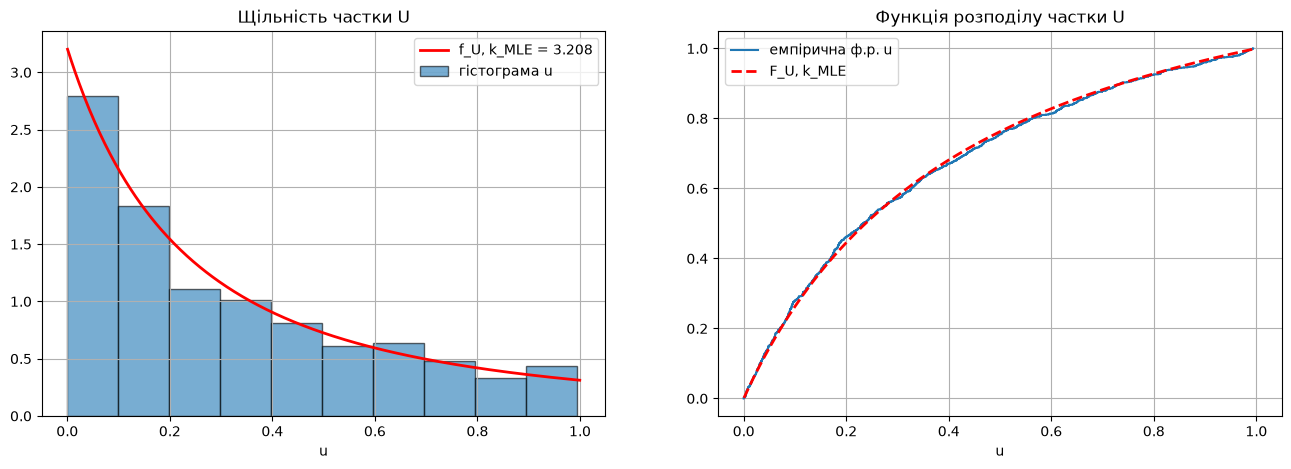

In [51]:
K = sturges(n)
t, counts, heights = my_hist(u, K)
h = t[1] - t[0]
y, F = my_ecdf(u)
s = np.linspace(0.0005, 0.9995, 400)

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
ax[0].bar(t[:-1], heights, width=h, align="edge", alpha=0.6, edgecolor="black", label="гістограма u")
ax[0].plot(s, k_mle / (1 + (k_mle - 1) * s) ** 2, "r", lw=2, label="f_U, k_MLE = {:.3f}".format(k_mle))
ax[1].step([0] + y, [0] + F, where="post", label="емпірична ф.р. u")
ax[1].plot(s, k_mle * s / (1 + (k_mle - 1) * s), "r--", lw=2, label="F_U, k_MLE")
for a_ in ax:
    a_.grid()
    a_.legend()
    a_.set_xlabel("u")
ax[0].set_title("Щільність частки U")
ax[1].set_title("Функція розподілу частки U")
plt.show()

Теоретичні $f_U$ та $F_U$ з $\hat k^{MLE}$ добре лягають на гістограму та емпіричну функцію розподілу.

### Імітаційна демонстрація неідентифіковності $\lambda$

Генеруємо частки для трьох наборів параметрів:
- $(\lambda=\hat\lambda\approx0.01,\ k=\hat k)$ — «наш» магазин;
- $(\lambda=1,\ k=\hat k)$ — ціни в ~100 разів менші;
- $(\lambda=\hat\lambda,\ k=1)$ — інше $k$.

Якщо розподіл $U$ не залежить від $\lambda$, перші дві емпіричні функції розподілу мають збігтися, а третя — відрізнятися.

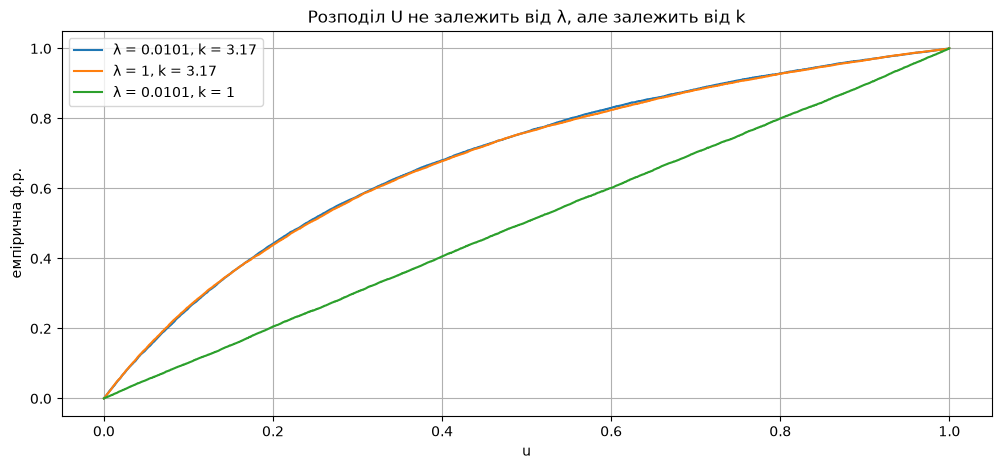

λ≈0.01, k=k_hat:  med(U) = 0.2387,  k_med = 3.190
λ=1,    k=k_hat:  med(U) = 0.2416,  k_med = 3.140
λ≈0.01, k=1   :  med(U) = 0.4962,  k_med = 1.015


In [52]:
n_sim = 20000


def simulate_U(lambd, k, m):
    x = np.random.exponential(1 / lambd, size=m)          # ξ ~ Exp(λ)
    y = np.random.exponential(1 / (lambd * k), size=m)    # η ~ Exp(λk)
    return y / (x + y)


U1 = simulate_U(lambda_hat, k_hat, n_sim)
U2 = simulate_U(1.0, k_hat, n_sim)
U3 = simulate_U(lambda_hat, 1.0, n_sim)

plt.figure(figsize=(12, 5))
for Us, lab in [(U1, "λ = {:.4f}, k = {:.2f}".format(lambda_hat, k_hat)),
                (U2, "λ = 1, k = {:.2f}".format(k_hat)),
                (U3, "λ = {:.4f}, k = 1".format(lambda_hat))]:
    yy, FF = my_ecdf(Us)
    plt.step(yy, FF, where="post", label=lab)
plt.xlabel("u")
plt.ylabel("емпірична ф.р.")
plt.title("Розподіл U не залежить від λ, але залежить від k")
plt.grid()
plt.legend()
plt.show()

for Us, lab in [(U1, "λ≈0.01, k=k_hat"), (U2, "λ=1,    k=k_hat"), (U3, "λ≈0.01, k=1   ")]:
    mm = med(Us)
    print("{}:  med(U) = {:.4f},  k_med = {:.3f}".format(lab, mm, (1 - mm) / mm))

Криві для $\lambda\approx0.01$ і $\lambda=1$ (при однаковому $k$) **зливаються**, а крива для $k=1$ — пряма $F(u)=u$ — суттєво інша. За вибіркою часток ми «бачимо» $k$, але не «бачимо» $\lambda$.

### Імітаційна перевірка коефіцієнтів розсіювання

Генеруємо $B$ вибірок обсягу $n$, по кожній обчислюємо всі оцінки. Нормоване зміщення $\sqrt n(\text{середнє оцінок}-k)$ має бути малим, а $n\cdot$(вибіркова дисперсія оцінок) — близьким до коефіцієнта розсіювання $v$. ОМВ і моментну оцінку шукаємо бісекцією одразу для всіх $B$ вибірок (векторизовано).

In [53]:
k_true = k_hat
B = 1000
m = 1000

x = np.random.exponential(1 / lambda_hat, size=(B, m))
y = np.random.exponential(1 / (lambda_hat * k_true), size=(B, m))
Us = y / (x + y)

# (б) медіанна
md_ = np.median(Us, axis=1)
est_med = (1 - md_) / md_

# (в) ОМВ: бісекція для всіх B вибірок одночасно
lo = np.full(B, 0.01)
hi = np.full(B, 100.0)
for _ in range(60):
    mid = (lo + hi) / 2
    sc = m / mid - 2 * (Us / (1 + (mid[:, None] - 1) * Us)).sum(axis=1)
    lo = np.where(sc > 0, mid, lo)
    hi = np.where(sc > 0, hi, mid)
est_mle = (lo + hi) / 2

# (а) метод моментів: H(k) спадає, бісекція для всіх B вибірок
ubar = Us.mean(axis=1)
lo = np.full(B, 0.01)
hi = np.full(B, 100.0)
for _ in range(60):
    mid = (lo + hi) / 2
    Hm = np.where(np.abs(mid - 1) < 1e-8, 0.5, (mid * np.log(mid) - mid + 1) / (mid - 1) ** 2)
    lo = np.where(Hm > ubar, mid, lo)
    hi = np.where(Hm > ubar, hi, mid)
est_mm = (lo + hi) / 2

# оцінка з розділу 3 за тими самими даними
est_full = x.mean(axis=1) / y.mean(axis=1)

rows = []
for name, est, v in [("ξ̄/η̄", est_full, 2 * k_true ** 2),
                     ("ОМВ за u", est_mle, 3 * k_true ** 2),
                     ("метод моментів за u", est_mm, var_U(k_true) / dH_U(k_true) ** 2),
                     ("медіанна за u", est_med, 4 * k_true ** 2)]:
    rows.append([name, est.mean(), math.sqrt(m) * (est.mean() - k_true), m * est.var(), v])
print("справжнє k = {:.4f},  n = {},  B = {}".format(k_true, m, B))
pd.DataFrame(rows, columns=["оцінка", "середнє", "sqrt(n)·зміщення", "n·D(оцінки)", "теор. v"])

справжнє k = 3.1659,  n = 1000,  B = 1000


,оцінка,середнє,sqrt(n)·зміщення,n·D(оцінки),теор. v
0,ξ̄/η̄,3.177075,0.353292,20.518479,20.045889
1,ОМВ за u,3.185417,0.617085,29.609535,30.068834
2,метод моментів за u,3.188061,0.700669,32.741658,32.825653
3,медіанна за u,3.187730,0.690219,40.614925,40.091778


Значення $n\cdot\mathrm D$ близькі до теоретичних коефіцієнтів розсіювання, нормовані зміщення малі. Порядок точності оцінок підтверджено.

### Зв'язок з розділом 4

За $F_U$ можна обчислити, яку частку замовлень модель відносить до зони $u\le0.1$:
$$
F_U(0.1)=\frac{0.1\,\hat k}{1+(\hat k-1)\cdot0.1}=\frac{0.3208}{1.2208}=0.2628\quad(\hat k^{MLE}),\qquad 0.2602\quad(\hat k=\bar\xi/\bar\eta).
$$
Обидва значення лежать у довірчому інтервалі для частки повернень [0.2502; 0.3058] з розділу 1. Отже, **весь** обсяг повернень пояснюється правилом «повертають, якщо частка с.п. не більша за 10%» разом з експоненційною моделлю цін.

## Відповідь на варіант 1

| Параметр | Чи можна оцінити за вибіркою $\frac{\eta_i}{\xi_i+\eta_i}$ | Обґрунтування |
|---|---|---|
| $k$ | **так** | $F_U(u)=\frac{ku}{1+(k-1)u}$ строго монотонна по $k$; строго консистентні оцінки $\hat k^{MM}=3.1436$, $\hat k^{med}=3.2894$, $\hat k^{MLE}=3.2085$ |
| $\lambda$ | **ні** | $F_U$ не залежить від $\lambda$ (частка інваріантна до масштабу цін) ⇒ розподіл даних не визначає $\lambda$ однозначно, конзистентної оцінки не існує |
| $\lambda$ і $k$ разом | **ні** | бо $\lambda$ неможливо |

# 5. Загальні висновки

| Що оцінювали | Оцінка | Інтервал, $\alpha=0.05$ | Інтервал, $\alpha=0.01$ |
|---|---|---|---|
| ймовірність повернення $p$ | 0.278 | [0.2502; 0.3058] | [0.2415; 0.3145] |
| $\mathrm E\eta$ — ціна товару по с.п. | 31.3233 | [29.3618; 33.2848] | [28.7455; 33.9012] |
| $\mathrm E\xi$ — ціна інших товарів | 99.1665 | [93.1128; 105.2203] | [91.2106; 107.1225] |
| $\lambda k$ | 0.031925 | — | — |
| $\lambda$ | 0.010084 | — | — |
| $k=\bar\xi/\bar\eta$ | 3.1659 | [2.8884; 3.4434] | [2.8012; 3.5306] |

1. **Повернення.** Близько 27.8% товарів по с.п. повертають. Відносна частота — ОМВ, незміщена й строго конзистентна. Обидва методи побудови інтервалу при $n=1000$ практично збігаються.
2. **Розподіли цін.** Вартості товарів по с.п. та інших товарів добре описуються експоненційним розподілом: гістограми, емпіричні функції розподілу, Q-Q-діаграми, тест $\chi^2$ з групуванням. $\xi$ та $\eta$ незалежні (тест кореляції Пірсона та тест $\chi^2$ незалежності).
3. **Властивості оцінок.** $\hat\lambda=1/\bar\xi$ та $\hat k=\bar\xi/\bar\eta$ **зміщені** (в $\frac{n}{n-1}$ разів), але **асимптотично незміщені й строго конзистентні**. Незміщені версії отримуємо множенням на $\frac{n-1}{n}$. Доведено через розподіл Ерланга і теорему 8.1., перевірено імітаційним експериментом.
4. **Недоброчесна поведінка доведена.** Повернення повністю визначаються часткою с.п. у кошику: всі замовлення з $u\le0.1$ повернені, жодне інше — ні. Тест $\chi^2$ незалежності та тест за довірчими інтервалами відхиляють гіпотезу про відсутність залежності. Типовий «схемщик» купує товар по с.п. за ~8.20 грн разом з кошиком за ~166.51 грн і повертає акційний товар. Обсяг — ~0.278 усіх замовлень, втрати лише на доставці ≈5560 грн на 1000 замовлень.
5. **Варіант 1.** За вибіркою часток $\frac{\eta_i}{\xi_i+\eta_i}$ можна консистентно оцінити $k$ (≈3.2, узгоджується з $\bar\xi/\bar\eta$), але **неможливо** оцінити $\lambda$: частка інваріантна до масштабу цін. Серед трьох методів найточніша ОМВ ($v=3k^2$), проте вона поступається оцінці за повними даними ($v=2k^2$).